In [1]:

import torch
import shutil

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    props = torch.cuda.get_device_properties(0)
    print(f"Total GPU memory: {props.total_memory / 1024**3:.2f} GB")
    print(
        f"Currently allocated: "
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
    )
else:
    print("No GPU detected. Enable a GPU runtime before training.")

total, used, free = shutil.disk_usage("/content")
print(f"Free disk space: {free / 1024**3:.2f} GB")


CUDA available: True
GPU: Tesla T4
Total GPU memory: 14.56 GB
Currently allocated: 0.00 GB
Free disk space: 70.28 GB


In [2]:
import torch
import torchvision
import os

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
), "GB")

print("Working directory:", os.getcwd())

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA: True
GPU: Tesla T4
GPU memory: 14.56 GB
Working directory: /content


In [3]:
from datasets import load_dataset

dataset = load_dataset("nobg/COD10K")

print(dataset)
print("Available splits:", list(dataset.keys()))

for split_name in dataset:
    print(f"\n{split_name}: {len(dataset[split_name])} samples")
    print("Columns:", dataset[split_name].column_names)

README.md:   0%|          | 0.00/1.95k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  492MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  454MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

...

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  297MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3040 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2026 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'mask'],
        num_rows: 3040
    })
    test: Dataset({
        features: ['image', 'mask'],
        num_rows: 2026
    })
})
Available splits: ['train', 'test']

train: 3040 samples
Columns: ['image', 'mask']

test: 2026 samples
Columns: ['image', 'mask']


Sample fields: dict_keys(['image', 'mask'])


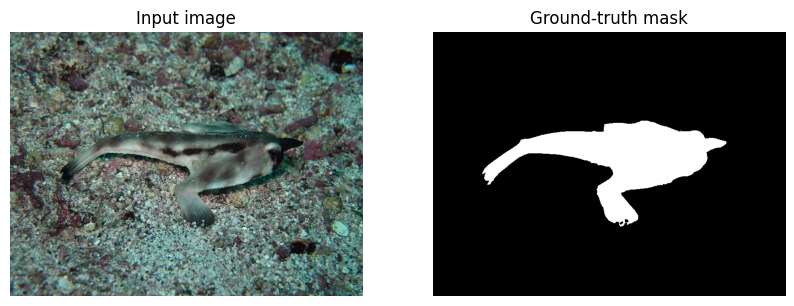

In [4]:
import matplotlib.pyplot as plt

train_split = dataset["train"]
sample = train_split[0]

print("Sample fields:", sample.keys())

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample["image"])
plt.title("Input image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sample["mask"], cmap="gray")
plt.title("Ground-truth mask")
plt.axis("off")

plt.show()

In [6]:
%pip install -q git+https://github.com/facebookresearch/segment-anything.git

  Preparing metadata (setup.py) ... done


In [9]:
import torch
from segment_anything import sam_model_registry

print("SAM import successful")
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

SAM import successful
CUDA: True
GPU: Tesla T4


In [8]:
import os
import torch

CHECKPOINT_PATH = "/content/sam_vit_b_01ec64.pth"

print("Checkpoint exists:", os.path.exists(CHECKPOINT_PATH))

if os.path.exists(CHECKPOINT_PATH):
    print(
        "Checkpoint size:",
        round(os.path.getsize(CHECKPOINT_PATH) / (1024**2), 1),
        "MB"
    )

print("Available GPU memory:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
), "GB")

Checkpoint exists: False
Available GPU memory: 14.56 GB


In [10]:
import os
import urllib.request

CHECKPOINT_PATH = "/content/sam_vit_b_01ec64.pth"
CHECKPOINT_URL = (
    "https://dl.fbaipublicfiles.com/segment_anything/"
    "sam_vit_b_01ec64.pth"
)

if not os.path.exists(CHECKPOINT_PATH):
    print("Downloading SAM ViT-B checkpoint...")
    urllib.request.urlretrieve(CHECKPOINT_URL, CHECKPOINT_PATH)

size_mb = os.path.getsize(CHECKPOINT_PATH) / (1024 ** 2)
print(f"Checkpoint downloaded: {size_mb:.1f} MB")
print("Checkpoint exists:", os.path.isfile(CHECKPOINT_PATH))

Checkpoint downloaded: 357.7 MB
Checkpoint exists: True


In [11]:
from segment_anything import sam_model_registry

sam = sam_model_registry["vit_b"](
    checkpoint=CHECKPOINT_PATH
)

# Enable training for the complete SAM image encoder.
for param in sam.image_encoder.parameters():
    param.requires_grad = True

# Keep the prompt encoder fixed.
for param in sam.prompt_encoder.parameters():
    param.requires_grad = False

# Train the mask decoder.
for param in sam.mask_decoder.parameters():
    param.requires_grad = True

encoder_total = sum(
    p.numel() for p in sam.image_encoder.parameters()
)
encoder_trainable = sum(
    p.numel() for p in sam.image_encoder.parameters()
    if p.requires_grad
)

print(f"Encoder parameters: {encoder_total:,}")
print(f"Trainable encoder parameters: {encoder_trainable:,}")
print(
    "Encoder fully trainable:",
    encoder_total == encoder_trainable
)

Encoder parameters: 89,670,912
Trainable encoder parameters: 89,670,912
Encoder fully trainable: True


In [12]:
import torch
from torch.utils.checkpoint import checkpoint

# Freeze the prompt encoder; keep image encoder and mask decoder trainable.
for p in sam.prompt_encoder.parameters():
    p.requires_grad = False

for p in sam.image_encoder.parameters():
    p.requires_grad = True

for p in sam.mask_decoder.parameters():
    p.requires_grad = True

# Enable gradient checkpointing on the image encoder's transformer blocks.
for block in sam.image_encoder.blocks:
    block.use_checkpoint = True

# Keep the model in training mode.
sam.train()

print("Image encoder trainable:",
      all(p.requires_grad for p in sam.image_encoder.parameters()))
print("Prompt encoder frozen:",
      all(not p.requires_grad for p in sam.prompt_encoder.parameters()))
print("Mask decoder trainable:",
      any(p.requires_grad for p in sam.mask_decoder.parameters()))

Image encoder trainable: True
Prompt encoder frozen: True
Mask decoder trainable: True


In [14]:
import torch

device = torch.device("cuda")
sam = sam.to(device)
sam.image_encoder.train()

optimizer = torch.optim.AdamW(
    sam.image_encoder.parameters(),
    lr=1e-6
)

# SAM ViT-B expects a 1024x1024 image canvas.
test_image = torch.randn(
    1, 3, 1024, 1024,
    device=device,
    dtype=torch.float32
)

optimizer.zero_grad(set_to_none=True)
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

before = next(sam.image_encoder.parameters()).detach().clone()

try:
    with torch.autocast("cuda", dtype=torch.float16):
        features = sam.image_encoder(test_image)
        loss = features.float().square().mean()

    loss.backward()

    first_param = next(sam.image_encoder.parameters())
    grad = first_param.grad

    print("Loss:", loss.item())
    print("Gradient exists:", grad is not None)
    print(
        "Gradient nonzero:",
        grad is not None and grad.abs().sum().item() > 0
    )

    optimizer.step()

    print(
        "Weights changed:",
        not torch.equal(before, first_param.detach())
    )
    print(
        "Peak VRAM (GB):",
        round(torch.cuda.max_memory_allocated() / 1024**3, 2)
    )

except torch.cuda.OutOfMemoryError:
    print("CUDA out of memory. Stop here; do not start training yet.")
    raise

finally:
    optimizer.zero_grad(set_to_none=True)
    del test_image
    torch.cuda.empty_cache()

Loss: 0.023826170712709427
Gradient exists: True
Gradient nonzero: False
Weights changed: False
Peak VRAM (GB): 8.55


In [15]:
import torch

sam.image_encoder.train()
sam.image_encoder.zero_grad(set_to_none=True)
torch.cuda.empty_cache()

test_image = torch.randn(
    1, 3, 1024, 1024,
    device="cuda"
)

try:
    with torch.autocast("cuda", dtype=torch.float16):
        features = sam.image_encoder(test_image)
        loss = features.float().square().mean()

    loss.backward()

    total_params = 0
    params_with_grad = 0
    params_with_nonzero_grad = 0
    total_nonzero_grad_elements = 0
    total_grad_norm_sq = 0.0

    for p in sam.image_encoder.parameters():
        total_params += 1

        if p.grad is not None:
            params_with_grad += 1
            nonzero = torch.count_nonzero(p.grad).item()

            if nonzero > 0:
                params_with_nonzero_grad += 1
                total_nonzero_grad_elements += nonzero

            total_grad_norm_sq += p.grad.detach().float().square().sum().item()

    print("Diagnostic loss:", loss.item())
    print("Encoder parameter tensors:", total_params)
    print("Tensors with gradients:", params_with_grad)
    print("Tensors with nonzero gradients:", params_with_nonzero_grad)
    print("Nonzero gradient elements:", total_nonzero_grad_elements)
    print("Overall gradient norm:", total_grad_norm_sq ** 0.5)

finally:
    sam.image_encoder.zero_grad(set_to_none=True)
    del test_image
    if "features" in locals():
        del features
    if "loss" in locals():
        del loss
    torch.cuda.empty_cache()

Diagnostic loss: 0.023868873715400696
Encoder parameter tensors: 177
Tensors with gradients: 177
Tensors with nonzero gradients: 6
Nonzero gradient elements: 579588
Overall gradient norm: 0.09591140506135035


In [16]:
for name, p in sam.image_encoder.named_parameters():
    if p.grad is not None:
        nz = torch.count_nonzero(p.grad).item()
        if nz > 0:
            print(
                name,
                "| shape:", tuple(p.shape),
                "| nonzero gradients:", nz,
                "| total elements:", p.numel(),
                "| grad norm:", p.grad.detach().float().norm().item()
            )

In [17]:
sam.image_encoder.zero_grad(set_to_none=True)

In [18]:
from torch.utils.data import random_split

full_train = dataset["train"]

val_size = int(0.1 * len(full_train))
train_size = len(full_train) - val_size

generator = torch.Generator().manual_seed(42)
train_data, val_data = random_split(
    full_train,
    [train_size, val_size],
    generator=generator
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images held out:", len(dataset["test"]))

Training images: 2736
Validation images: 304
Test images held out: 2026


In [19]:
import torch
import numpy as np
from PIL import Image

sample = train_data[0]
image = sample["image"].convert("RGB")

# Resize for this shape-only diagnostic.
image = image.resize((1024, 1024))
image_tensor = torch.from_numpy(
    np.array(image).copy()
).permute(2, 0, 1).float()

image_tensor = image_tensor.unsqueeze(0).cuda()
image_tensor = sam.preprocess(image_tensor[0]).unsqueeze(0)

print("SAM input shape:", tuple(image_tensor.shape))

SAM input shape: (1, 3, 1024, 1024)


In [20]:
sam.eval()
sam.image_encoder.eval()
sam.prompt_encoder.eval()
sam.mask_decoder.eval()

torch.cuda.empty_cache()

try:
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        image_embedding = sam.image_encoder(image_tensor)

        sparse_embeddings, dense_embeddings = sam.prompt_encoder(
            points=None,
            boxes=None,
            masks=None
        )

        low_res_masks, iou_predictions = sam.mask_decoder(
            image_embeddings=image_embedding,
            image_pe=sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_embeddings,
            dense_prompt_embeddings=dense_embeddings,
            multimask_output=False
        )

    print("Image embedding:", tuple(image_embedding.shape))
    print("Low-resolution mask:", tuple(low_res_masks.shape))
    print("IoU predictions:", tuple(iou_predictions.shape))

finally:
    del image_embedding, sparse_embeddings, dense_embeddings
    del low_res_masks, iou_predictions
    torch.cuda.empty_cache()

Image embedding: (1, 256, 64, 64)
Low-resolution mask: (1, 1, 256, 256)
IoU predictions: (1, 1)


In [21]:
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class COD10KDataset(Dataset):
    def __init__(self, hf_dataset, indices, image_size=1024):
        self.data = hf_dataset
        self.indices = indices
        self.image_size = image_size

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        item = self.data[self.indices[idx]]

        image = item["image"].convert("RGB")
        mask = item["mask"].convert("L")

        # Resize RGB image and mask to the same spatial dimensions.
        image = image.resize(
            (self.image_size, self.image_size),
            Image.Resampling.BILINEAR
        )
        mask = mask.resize(
            (self.image_size, self.image_size),
            Image.Resampling.NEAREST
        )

        image = torch.from_numpy(
            np.array(image).copy()
        ).permute(2, 0, 1).float()

        mask = torch.from_numpy(
            np.array(mask).copy()
        ).unsqueeze(0).float() / 255.0

        mask = (mask >= 0.5).float()
        return image, mask


# random_split returns Subset objects; recover their original indices.
train_indices = train_data.indices
val_indices = val_data.indices

train_ds = COD10KDataset(full_train, train_indices)
val_ds = COD10KDataset(full_train, val_indices)

train_loader = DataLoader(
    train_ds, batch_size=1, shuffle=True,
    num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=1, shuffle=False,
    num_workers=2, pin_memory=True
)

def segmentation_loss(logits, target):
    target = F.interpolate(
        target, size=logits.shape[-2:], mode="nearest"
    )

    bce = F.binary_cross_entropy_with_logits(logits, target)

    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)
    intersection = (probs * target).sum(dims)
    denominator = probs.sum(dims) + target.sum(dims)

    dice = 1 - ((2 * intersection + 1e-6) /
                (denominator + 1e-6)).mean()

    return bce + dice

In [22]:
import torch

device = "cuda"
sam = sam.to(device)

# Enable encoder and decoder training; keep prompt encoder frozen.
for p in sam.image_encoder.parameters():
    p.requires_grad = True

for p in sam.prompt_encoder.parameters():
    p.requires_grad = False

for p in sam.mask_decoder.parameters():
    p.requires_grad = True

# Small learning rates for pretrained weights.
optimizer = torch.optim.AdamW([
    {"params": sam.image_encoder.parameters(), "lr": 1e-6},
    {"params": sam.mask_decoder.parameters(), "lr": 1e-5},
], weight_decay=1e-4)

images, masks = next(iter(train_loader))
images = images.to(device)
masks = masks.to(device)

# SAM preprocess expects 0–255 RGB tensors.
images = torch.stack([sam.preprocess(img) for img in images])

optimizer.zero_grad(set_to_none=True)
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

try:
    sam.train()

    with torch.autocast("cuda", dtype=torch.float16):
        image_embeddings = sam.image_encoder(images)

        with torch.no_grad():
            sparse_embeddings, dense_embeddings = sam.prompt_encoder(
                points=None, boxes=None, masks=None
            )

        logits, iou_predictions = sam.mask_decoder(
            image_embeddings=image_embeddings,
            image_pe=sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_embeddings,
            dense_prompt_embeddings=dense_embeddings,
            multimask_output=False
        )

        loss = segmentation_loss(logits.float(), masks)

    loss.backward()

    encoder_grad = sum(
        p.grad.detach().float().norm().item()
        for p in sam.image_encoder.parameters()
        if p.grad is not None
    )
    decoder_grad = sum(
        p.grad.detach().float().norm().item()
        for p in sam.mask_decoder.parameters()
        if p.grad is not None
    )

    print("Segmentation loss:", loss.item())
    print("Encoder gradient norm sum:", encoder_grad)
    print("Decoder gradient norm sum:", decoder_grad)
    print("Peak VRAM (GB):", round(
        torch.cuda.max_memory_allocated() / 1024**3, 2
    ))

except torch.cuda.OutOfMemoryError:
    print("Out of memory during segmentation backward pass.")
    raise

finally:
    optimizer.zero_grad(set_to_none=True)
    del images, masks, image_embeddings, logits, iou_predictions
    torch.cuda.empty_cache()

Segmentation loss: 1.4004368782043457
Encoder gradient norm sum: 70.43513891100883
Decoder gradient norm sum: 285.3511177077635
Peak VRAM (GB): 8.59


In [23]:
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class COD10KDataset(Dataset):
    def __init__(self, hf_dataset, indices, image_size=1024):
        self.data = hf_dataset
        self.indices = indices
        self.image_size = image_size

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        item = self.data[self.indices[idx]]

        image = item["image"].convert("RGB")
        mask = item["mask"].convert("L")

        w, h = image.size
        scale = self.image_size / max(w, h)
        nw = max(1, round(w * scale))
        nh = max(1, round(h * scale))

        image = image.resize(
            (nw, nh), Image.Resampling.BILINEAR
        )
        mask = mask.resize(
            (nw, nh), Image.Resampling.NEAREST
        )

        image_arr = np.asarray(image).copy()
        mask_arr = np.asarray(mask).copy()

        image_tensor = torch.from_numpy(image_arr).permute(2, 0, 1).float()
        mask_tensor = torch.from_numpy(mask_arr).float().unsqueeze(0) / 255.0
        mask_tensor = (mask_tensor >= 0.5).float()

        # Pad on right and bottom; matches SAM's longest-side resize pipeline.
        image_tensor = F.pad(
            image_tensor,
            (0, self.image_size - nw, 0, self.image_size - nh)
        )
        mask_tensor = F.pad(
            mask_tensor,
            (0, self.image_size - nw, 0, self.image_size - nh)
        )

        return image_tensor, mask_tensor

In [24]:
train_ds = COD10KDataset(full_train, train_indices)
val_ds = COD10KDataset(full_train, val_indices)

train_loader = DataLoader(
    train_ds, batch_size=1, shuffle=True,
    num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=1, shuffle=False,
    num_workers=2, pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 2736
Validation batches: 304


In [25]:
from torch.utils.checkpoint import checkpoint

for block in sam.image_encoder.blocks:
    original_forward = block.forward

    def make_checkpointed_forward(original_forward):
        def forward_with_checkpoint(self, x):
            if self.training and torch.is_grad_enabled():
                return checkpoint(
                    original_forward, x, use_reentrant=False
                )
            return original_forward(x)
        return forward_with_checkpoint

    block.forward = make_checkpointed_forward(original_forward).__get__(
        block, type(block)
    )

print("Checkpointing wrappers installed:", len(sam.image_encoder.blocks))

Checkpointing wrappers installed: 12


In [26]:
import os
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

device = "cuda"
sam = sam.to(device)

for p in sam.image_encoder.parameters():
    p.requires_grad = True

for p in sam.prompt_encoder.parameters():
    p.requires_grad = False

for p in sam.mask_decoder.parameters():
    p.requires_grad = True

optimizer = torch.optim.AdamW([
    {"params": sam.image_encoder.parameters(), "lr": 1e-6},
    {"params": sam.mask_decoder.parameters(), "lr": 1e-5},
], weight_decay=1e-4)

scaler = torch.amp.GradScaler("cuda")

def segmentation_loss(logits, target):
    target = F.interpolate(
        target, size=logits.shape[-2:], mode="nearest"
    )
    bce = F.binary_cross_entropy_with_logits(logits, target)
    probs = torch.sigmoid(logits)
    intersection = (probs * target).sum((1, 2, 3))
    denominator = probs.sum((1, 2, 3)) + target.sum((1, 2, 3))
    dice = 1 - ((2 * intersection + 1e-6) /
                (denominator + 1e-6)).mean()
    return bce + dice

def forward_batch(images):
    images = torch.stack([sam.preprocess(img) for img in images])

    embeddings = sam.image_encoder(images)

    with torch.no_grad():
        sparse, dense = sam.prompt_encoder(
            points=None, boxes=None, masks=None
        )

    logits, _ = sam.mask_decoder(
        image_embeddings=embeddings,
        image_pe=sam.prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=sparse,
        dense_prompt_embeddings=dense,
        multimask_output=False
    )
    return logits

# Verify the model weights will be updated during training.
first_encoder_param = next(sam.image_encoder.parameters())
encoder_before = first_encoder_param.detach().clone()

sam.train()
total_loss = 0.0
successful_steps = 0
torch.cuda.reset_peak_memory_stats()

for images, masks in tqdm(train_loader, desc="Training epoch 1"):
    images = images.to(device, non_blocking=True)
    masks = masks.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    try:
        with torch.autocast("cuda", dtype=torch.float16):
            logits = forward_batch(images)
            loss = segmentation_loss(logits.float(), masks)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            [p for p in sam.parameters() if p.requires_grad],
            max_norm=1.0
        )
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        successful_steps += 1

    except torch.cuda.OutOfMemoryError:
        optimizer.zero_grad(set_to_none=True)
        torch.cuda.empty_cache()
        raise RuntimeError(
            "GPU ran out of memory. Stop and reduce memory use before retrying."
        )

    finally:
        if "logits" in locals():
            del logits
        if "loss" in locals():
            del loss

    if successful_steps % 100 == 0:
        torch.cuda.empty_cache()

print("Training steps:", successful_steps)
print("Mean training loss:", total_loss / max(successful_steps, 1))
print(
    "Encoder parameter changed:",
    not torch.equal(encoder_before, first_encoder_param.detach())
)
print(
    "Peak VRAM (GB):",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2)
)

os.makedirs("/content/sam_cod10k_checkpoints", exist_ok=True)
torch.save(
    sam.state_dict(),
    "/content/sam_cod10k_checkpoints/sam_vit_b_epoch1.pth"
)
print("Checkpoint saved.")

Training epoch 1:   0%|          | 0/2736 [00:00<?, ?it/s]

Training steps: 2736
Mean training loss: 0.48123715796619543
Encoder parameter changed: True
Peak VRAM (GB): 4.15
Checkpoint saved.


In [27]:
sam.eval()
val_loss = 0.0

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Validation"):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16):
            logits = forward_batch(images)
            loss = segmentation_loss(logits.float(), masks)

        val_loss += loss.item()

print("Validation loss:", val_loss / len(val_loader))

Validation:   0%|          | 0/304 [00:00<?, ?it/s]

Validation loss: 0.3930091459402128


In [30]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [31]:
from google.colab import drive
drive.mount("/content/drive")

import os
import shutil

drive_dir = "/content/drive/MyDrive/COD10K_SAM"
os.makedirs(drive_dir, exist_ok=True)

shutil.copy2(
    "/content/sam_cod10k_checkpoints/sam_vit_b_epoch1.pth",
    f"{drive_dir}/sam_vit_b_epoch1.pth"
)

print("Checkpoint backed up to Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint backed up to Google Drive.


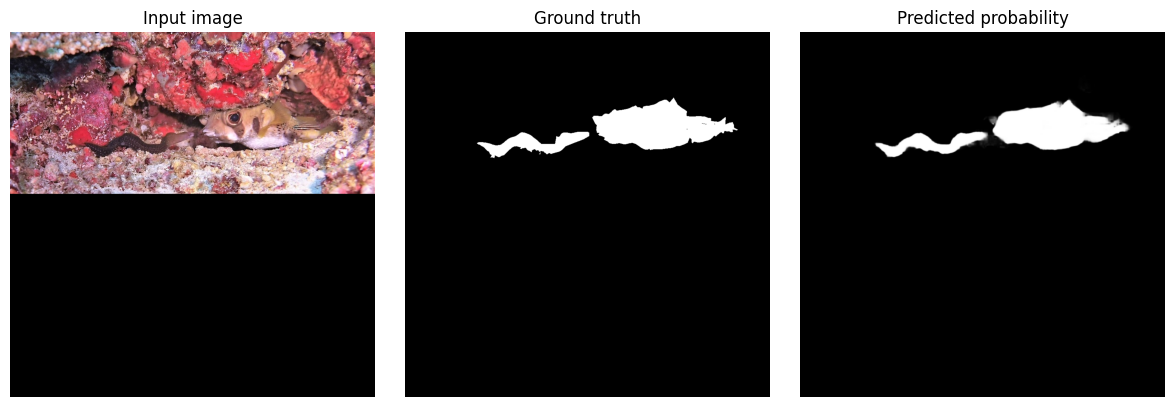

In [32]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

sam.eval()
images, masks = next(iter(val_loader))

image = images[0].cuda()
gt = masks[0, 0].cpu().numpy()

with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    processed = sam.preprocess(image)
    embedding = sam.image_encoder(processed.unsqueeze(0))

    sparse, dense = sam.prompt_encoder(
        points=None, boxes=None, masks=None
    )

    logits, _ = sam.mask_decoder(
        image_embeddings=embedding,
        image_pe=sam.prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=sparse,
        dense_prompt_embeddings=dense,
        multimask_output=False
    )

    prediction = torch.sigmoid(
        F.interpolate(
            logits.float(),
            size=(1024, 1024),
            mode="bilinear",
            align_corners=False
        )
    )[0, 0].cpu().numpy()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(images[0].permute(1, 2, 0).byte().numpy())
plt.title("Input image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gt, cmap="gray")
plt.title("Ground truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prediction, cmap="gray", vmin=0, vmax=1)
plt.title("Predicted probability")
plt.axis("off")

plt.tight_layout()
plt.show()

In [33]:
print("SAM model available:", "sam" in globals())
print("Validation loader available:", "val_loader" in globals())
print("Validation dataset available:", "val_ds" in globals())
print("GPU available:", torch.cuda.is_available())

SAM model available: True
Validation loader available: True
Validation dataset available: True
GPU available: True


In [35]:
%pip install -q pysodmetrics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 MB 15.2 MB/s eta 0:00:00


In [36]:
from py_sod_metrics import (
    MAE,
    Emeasure,
    Smeasure,
    WeightedFmeasure
)

print("All four COD evaluation metrics are ready!")

All four COD evaluation metrics are ready!


In [37]:
import torch
import torch.nn.functional as F
import numpy as np
from tqdm.auto import tqdm
from py_sod_metrics import MAE, Emeasure, Smeasure, WeightedFmeasure

device = next(sam.parameters()).device
sam.eval()

# Initialize COD evaluation metrics
mae_metric = MAE()
em_metric = Emeasure()
sm_metric = Smeasure()
wf_metric = WeightedFmeasure(beta=0.3)

iou_scores = []
dice_scores = []

@torch.no_grad()
def evaluate_cod():
    for batch in tqdm(val_loader, desc="Evaluating validation set"):
        # Expected dataset output: image tensor, mask tensor
        images, masks = batch[:2]
        images = images.to(device)
        masks = masks.to(device).float()

        # Forward pass through SAM
        # Keep the same preprocessing used during training
        processed = torch.stack([sam.preprocess(img) for img in images])
        image_embeddings = sam.image_encoder(processed)

        sparse_embeddings, dense_embeddings = sam.prompt_encoder(
            points=None,
            boxes=None,
            masks=None
        )

        low_res_logits, iou_predictions = sam.mask_decoder(
            image_embeddings=image_embeddings,
            image_pe=sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_embeddings,
            dense_prompt_embeddings=dense_embeddings,
            multimask_output=False
        )

        # Upsample predictions to the mask tensor dimensions
        logits = F.interpolate(
            low_res_logits,
            size=masks.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        probs = torch.sigmoid(logits).squeeze(1).cpu().numpy()
        gt = masks.squeeze(1).cpu().numpy()

        for pred, target in zip(probs, gt):
            # Convert to 8-bit grayscale maps for PySODMetrics
            pred_u8 = np.clip(pred * 255, 0, 255).astype(np.uint8)
            target_u8 = np.clip(target * 255, 0, 255).astype(np.uint8)

            mae_metric.step(pred=pred_u8, gt=target_u8)
            em_metric.step(pred=pred_u8, gt=target_u8)
            sm_metric.step(pred=pred_u8, gt=target_u8)
            wf_metric.step(pred=pred_u8, gt=target_u8)

            # Supplementary binary metrics (threshold = 0.5)
            pred_bin = pred >= 0.5
            gt_bin = target >= 0.5

            intersection = np.logical_and(pred_bin, gt_bin).sum()
            union = np.logical_or(pred_bin, gt_bin).sum()
            total = pred_bin.sum() + gt_bin.sum()

            iou_scores.append(
                intersection / union if union else 1.0
            )
            dice_scores.append(
                2 * intersection / total if total else 1.0
            )

evaluate_cod()

print("\n--- Validation Results ---")
print("MAE:", mae_metric.get_results()["mae"])
print("S-measure:", sm_metric.get_results()["sm"])
print("E-measure:", em_metric.get_results()["em"])
print("Weighted F-measure:", wf_metric.get_results()["wfm"])
print("IoU:", np.mean(iou_scores))
print("Dice:", np.mean(dice_scores))

Evaluating validation set:   0%|          | 0/304 [00:00<?, ?it/s]


--- Validation Results ---
MAE: 0.0310845585106075
S-measure: 0.8236020370287139
E-measure: {'adp': np.float64(0.843817007852419), 'curve': array([0.73451053, 0.79081849, 0.82518659, 0.84262783, 0.85350489,
       0.86069739, 0.86575343, 0.86940192, 0.8720676 , 0.87412428,
       0.87571576, 0.87693582, 0.87796412, 0.87885726, 0.87962793,
       0.88033964, 0.88084547, 0.88133833, 0.88177745, 0.88219343,
       0.88257044, 0.88297945, 0.883311  , 0.88360547, 0.88380341,
       0.88403474, 0.88427064, 0.88445953, 0.88465994, 0.88487277,
       0.88504585, 0.88521221, 0.88532667, 0.88546159, 0.88560898,
       0.88574484, 0.88589645, 0.88602773, 0.88612879, 0.88621523,
       0.88630487, 0.8863786 , 0.8864447 , 0.8865003 , 0.88656288,
       0.88664519, 0.88670512, 0.88674075, 0.88675618, 0.88679394,
       0.88683411, 0.88687307, 0.88689713, 0.88690641, 0.88689663,
       0.88692048, 0.88692513, 0.88691634, 0.88692164, 0.88691612,
       0.88689813, 0.88688936, 0.88689148, 0.88689765, 

In [38]:
sample = val_ds[0]

print("Sample type:", type(sample))

if isinstance(sample, dict):
    print("Keys:", sample.keys())
    for key, value in sample.items():
        if hasattr(value, "shape"):
            print(key, "shape:", value.shape, "dtype:", value.dtype)
elif isinstance(sample, (tuple, list)):
    for i, value in enumerate(sample):
        if hasattr(value, "shape"):
            print(f"Item {i}: shape={value.shape}, dtype={value.dtype}")
        else:
            print(f"Item {i}: type={type(value)}")

Sample type: <class 'tuple'>
Item 0: shape=torch.Size([3, 1024, 1024]), dtype=torch.float32
Item 1: shape=torch.Size([1, 1024, 1024]), dtype=torch.float32


In [39]:
import torch

image, mask = val_ds[0]

print("Image range:", image.min().item(), image.max().item())
print("Mask range:", mask.min().item(), mask.max().item())
print("Unique mask values (first 20):",
      torch.unique(mask)[:20].tolist())

# Check whether the image has black padding
pixel_sum = image.abs().sum(dim=0)
print("Completely black pixels:",
      (pixel_sum == 0).sum().item())

# Show mask foreground proportion
print("Mask foreground proportion:",
      (mask > 0.5).float().mean().item())

Image range: 0.0 255.0
Mask range: 0.0 1.0
Unique mask values (first 20): [0.0, 1.0]
Completely black pixels: 583680
Mask foreground proportion: 0.04155731201171875


In [42]:
print(inspect.getsource(val_ds.__getitem__))

    def __getitem__(self, idx):
        item = self.data[self.indices[idx]]

        image = item["image"].convert("RGB")
        mask = item["mask"].convert("L")

        w, h = image.size
        scale = self.image_size / max(w, h)
        nw = max(1, round(w * scale))
        nh = max(1, round(h * scale))

        image = image.resize(
            (nw, nh), Image.Resampling.BILINEAR
        )
        mask = mask.resize(
            (nw, nh), Image.Resampling.NEAREST
        )

        image_arr = np.asarray(image).copy()
        mask_arr = np.asarray(mask).copy()

        image_tensor = torch.from_numpy(image_arr).permute(2, 0, 1).float()
        mask_tensor = torch.from_numpy(mask_arr).float().unsqueeze(0) / 255.0
        mask_tensor = (mask_tensor >= 0.5).float()

        # Pad on right and bottom; matches SAM's longest-side resize pipeline.
        image_tensor = F.pad(
            image_tensor,
            (0, self.image_size - nw, 0, self.image_size - nh)
        )
        mask

In [43]:
item = val_ds.data[val_ds.indices[0]]
image = item["image"]

print("Original image size (width, height):", image.size)
print("Model input size:", val_ds[0][0].shape[-2:])

Original image size (width, height): (1024, 454)
Model input size: torch.Size([1024, 1024])


In [44]:
import torch
import torch.nn.functional as F
import numpy as np
from tqdm.auto import tqdm
from py_sod_metrics import MAE, Emeasure, Smeasure, WeightedFmeasure

device = next(sam.parameters()).device
sam.eval()

mae_metric = MAE()
em_metric = Emeasure()
sm_metric = Smeasure()
wf_metric = WeightedFmeasure(beta=0.3)

iou_scores = []
dice_scores = []

@torch.no_grad()
def evaluate_cod_unpadded():
    for batch_idx, (images, masks) in enumerate(
        tqdm(val_loader, desc="Evaluating without padding")
    ):
        images = images.to(device)
        masks = masks.to(device).float()

        processed = torch.stack([sam.preprocess(img) for img in images])
        embeddings = sam.image_encoder(processed)

        sparse, dense = sam.prompt_encoder(
            points=None, boxes=None, masks=None
        )

        logits, _ = sam.mask_decoder(
            image_embeddings=embeddings,
            image_pe=sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse,
            dense_prompt_embeddings=dense,
            multimask_output=False
        )

        logits = F.interpolate(
            logits,
            size=(1024, 1024),
            mode="bilinear",
            align_corners=False
        )

        probs = torch.sigmoid(logits).squeeze(1).cpu().numpy()
        targets = masks.squeeze(1).cpu().numpy()

        # Recover the corresponding original sample for each batch item.
        start = batch_idx * val_loader.batch_size

        for j, (pred, target) in enumerate(zip(probs, targets)):
            dataset_idx = start + j
            original_idx = val_ds.indices[dataset_idx]
            original_image = val_ds.data[original_idx]["image"]

            w, h = original_image.size
            scale = 1024 / max(w, h)
            nw = max(1, round(w * scale))
            nh = max(1, round(h * scale))

            # Exclude right/bottom padding.
            pred = pred[:nh, :nw]
            target = target[:nh, :nw]

            pred_u8 = np.clip(pred * 255, 0, 255).astype(np.uint8)
            target_u8 = (target >= 0.5).astype(np.uint8) * 255

            mae_metric.step(pred=pred_u8, gt=target_u8)
            em_metric.step(pred=pred_u8, gt=target_u8)
            sm_metric.step(pred=pred_u8, gt=target_u8)
            wf_metric.step(pred=pred_u8, gt=target_u8)

            pred_bin = pred >= 0.5
            gt_bin = target >= 0.5
            intersection = np.logical_and(pred_bin, gt_bin).sum()
            union = np.logical_or(pred_bin, gt_bin).sum()
            total = pred_bin.sum() + gt_bin.sum()

            iou_scores.append(intersection / union if union else 1.0)
            dice_scores.append(2 * intersection / total if total else 1.0)

evaluate_cod_unpadded()

em_results = em_metric.get_results()["em"]

print("\n--- Validation Results (padding excluded) ---")
print("MAE:", mae_metric.get_results()["mae"])
print("S-measure:", sm_metric.get_results()["sm"])
print("Adaptive E-measure:", em_results["adp"])
print("Maximum E-measure:", np.max(em_results["curve"]))
print("Weighted F-measure:", wf_metric.get_results()["wfm"])
print("IoU:", np.mean(iou_scores))
print("Dice:", np.mean(dice_scores))

Evaluating without padding:   0%|          | 0/304 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cefa46adf80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cefa46adf80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1655, in _shutdown_workers
    self._pin_memory_thread.join()
  File "/usr/lib/python3.13/threading.py", line 1088, in join
    raise RuntimeError("cannot join current thread")
RuntimeError: cannot join current thread
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/proc


--- Validation Results (padding excluded) ---
MAE: 0.045395084927408104
S-measure: 0.8160907732725184
Adaptive E-measure: 0.8424251128220179
Maximum E-measure: 0.8792979195376143
Weighted F-measure: 0.6620567503783013
IoU: 0.6423061021161898
Dice: 0.7399837637269785


In [46]:
from torch.utils.data import DataLoader

val_loader_safe = DataLoader(
    val_ds,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("Validation loader ready:", len(val_loader_safe), "images")

Validation loader ready: 304 images


In [47]:
import cv2
import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from py_sod_metrics import MAE, Emeasure, Smeasure, WeightedFmeasure

sam.eval()
device = next(sam.parameters()).device

mae_metric = MAE()
em_metric = Emeasure()
sm_metric = Smeasure()
wf_metric = WeightedFmeasure(beta=0.3)

iou_scores, dice_scores = [], []

with torch.no_grad():
    for idx, (images, masks) in enumerate(
        tqdm(val_loader_safe, desc="Original-resolution evaluation")
    ):
        images = images.to(device)
        processed = torch.stack([sam.preprocess(img) for img in images])
        embeddings = sam.image_encoder(processed)

        sparse, dense = sam.prompt_encoder(
            points=None, boxes=None, masks=None
        )
        logits, _ = sam.mask_decoder(
            image_embeddings=embeddings,
            image_pe=sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse,
            dense_prompt_embeddings=dense,
            multimask_output=False
        )

        # Probability map at 1024 x 1024
        probs = torch.sigmoid(
            F.interpolate(
                logits, size=(1024, 1024),
                mode="bilinear", align_corners=False
            )
        )[0, 0].cpu().numpy()

        # Retrieve original image and original ground-truth mask
        original_idx = val_ds.indices[idx]
        item = val_ds.data[original_idx]
        original_image = item["image"]
        original_mask = item["mask"].convert("L")

        w, h = original_image.size
        scale = 1024 / max(w, h)
        nw = max(1, round(w * scale))
        nh = max(1, round(h * scale))

        # Remove right/bottom padding
        probs = probs[:nh, :nw]

        # Resize prediction to the original image resolution
        pred_original = cv2.resize(
            probs, (w, h), interpolation=cv2.INTER_LINEAR
        )
        gt_original = np.asarray(original_mask)

        # Binary ground truth: 0 or 255
        gt_binary = (gt_original >= 128).astype(np.uint8) * 255
        pred_u8 = np.clip(
            pred_original * 255, 0, 255
        ).astype(np.uint8)

        mae_metric.step(pred=pred_u8, gt=gt_binary)
        em_metric.step(pred=pred_u8, gt=gt_binary)
        sm_metric.step(pred=pred_u8, gt=gt_binary)
        wf_metric.step(pred=pred_u8, gt=gt_binary)

        pred_bin = pred_original >= 0.5
        gt_bin = gt_original >= 128

        intersection = np.logical_and(pred_bin, gt_bin).sum()
        union = np.logical_or(pred_bin, gt_bin).sum()
        total = pred_bin.sum() + gt_bin.sum()

        iou_scores.append(intersection / union if union else 1.0)
        dice_scores.append(2 * intersection / total if total else 1.0)

em = em_metric.get_results()["em"]

print("\n--- Original-resolution validation results ---")
print(f"MAE: {mae_metric.get_results()['mae']:.4f}")
print(f"S-measure: {sm_metric.get_results()['sm']:.4f}")
print(f"Adaptive E-measure: {em['adp']:.4f}")
print(f"Maximum E-measure: {np.max(em['curve']):.4f}")
print(f"Weighted F-measure: {wf_metric.get_results()['wfm']:.4f}")
print(f"IoU: {np.mean(iou_scores):.4f}")
print(f"Dice: {np.mean(dice_scores):.4f}")

Original-resolution evaluation:   0%|          | 0/304 [00:00<?, ?it/s]


--- Original-resolution validation results ---
MAE: 0.0454
S-measure: 0.8162
Adaptive E-measure: 0.8421
Maximum E-measure: 0.8793
Weighted F-measure: 0.6622
IoU: 0.6424
Dice: 0.7400


In [48]:
import pandas as pd

results = {
    "Epoch": [1],
    "MAE": [0.0454],
    "S_measure": [0.8162],
    "Adaptive_E_measure": [0.8421],
    "Maximum_E_measure": [0.8793],
    "Weighted_F_measure": [0.6622],
    "IoU": [0.6424],
    "Dice": [0.7400],
}

baseline_df = pd.DataFrame(results)

baseline_path = "/content/sam_cod10k_epoch1_baseline.csv"
baseline_df.to_csv(baseline_path, index=False)

print(baseline_df.to_string(index=False))
print("\nSaved to:", baseline_path)


 Epoch    MAE  S_measure  Adaptive_E_measure  Maximum_E_measure  Weighted_F_measure    IoU  Dice
     1 0.0454     0.8162              0.8421             0.8793              0.6622 0.6424  0.74

Saved to: /content/sam_cod10k_epoch1_baseline.csv


In [49]:
import os
import pandas as pd

checkpoint_path = "/content/sam_cod10k_checkpoints/sam_vit_b_epoch1.pth"

print("Epoch 1 checkpoint exists:", os.path.isfile(checkpoint_path))

if os.path.isfile(checkpoint_path):
    print(
        "Checkpoint size (MB):",
        round(os.path.getsize(checkpoint_path) / (1024**2), 2)
    )

baseline = pd.DataFrame([{
    "epoch": 1,
    "MAE": 0.0454,
    "S_measure": 0.8162,
    "Adaptive_E_measure": 0.8421,
    "Maximum_E_measure": 0.8793,
    "Weighted_F_measure": 0.6622,
    "IoU": 0.6424,
    "Dice": 0.7400,
}])

baseline.to_csv(
    "/content/sam_cod10k_epoch1_baseline.csv",
    index=False
)

print("\nEpoch 1 baseline saved.")

Epoch 1 checkpoint exists: True
Checkpoint size (MB): 357.69

Epoch 1 baseline saved.


In [50]:
import torch

checkpoint_path = "/content/sam_cod10k_checkpoints/sam_vit_b_epoch1.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Top-level keys:", list(checkpoint.keys())[:30])
    print("Number of entries:", len(checkpoint))

Checkpoint type: <class 'collections.OrderedDict'>
Top-level keys: ['image_encoder.pos_embed', 'image_encoder.patch_embed.proj.weight', 'image_encoder.patch_embed.proj.bias', 'image_encoder.blocks.0.norm1.weight', 'image_encoder.blocks.0.norm1.bias', 'image_encoder.blocks.0.attn.rel_pos_h', 'image_encoder.blocks.0.attn.rel_pos_w', 'image_encoder.blocks.0.attn.qkv.weight', 'image_encoder.blocks.0.attn.qkv.bias', 'image_encoder.blocks.0.attn.proj.weight', 'image_encoder.blocks.0.attn.proj.bias', 'image_encoder.blocks.0.norm2.weight', 'image_encoder.blocks.0.norm2.bias', 'image_encoder.blocks.0.mlp.lin1.weight', 'image_encoder.blocks.0.mlp.lin1.bias', 'image_encoder.blocks.0.mlp.lin2.weight', 'image_encoder.blocks.0.mlp.lin2.bias', 'image_encoder.blocks.1.norm1.weight', 'image_encoder.blocks.1.norm1.bias', 'image_encoder.blocks.1.attn.rel_pos_h', 'image_encoder.blocks.1.attn.rel_pos_w', 'image_encoder.blocks.1.attn.qkv.weight', 'image_encoder.blocks.1.attn.qkv.bias', 'image_encoder.blocks

In [51]:
import torch

checkpoint_path = "/content/sam_cod10k_checkpoints/sam_vit_b_epoch1.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Load the fine-tuned weights into the existing SAM architecture
missing, unexpected = sam.load_state_dict(checkpoint, strict=True)

print("Checkpoint loaded successfully.")
print("Missing keys:", len(missing))
print("Unexpected keys:", len(unexpected))

Checkpoint loaded successfully.
Missing keys: 0
Unexpected keys: 0


In [52]:
print("GPU:", torch.cuda.is_available())
print("SAM loaded:", sam is not None)
print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Training loader batches:", len(train_loader))

GPU: True
SAM loaded: True
Training samples: 2736
Validation samples: 304
Training loader batches: 2736


In [57]:
import types
import torch
from torch.utils.checkpoint import checkpoint as torch_checkpoint

for block in sam.image_encoder.blocks:
    # Recover the original forward method saved by our earlier patch
    if hasattr(block, "_original_forward"):
        block.forward = block._original_forward

# Install a wrapper that explicitly calls torch_checkpoint
for block in sam.image_encoder.blocks:
    original_forward = block._original_forward

    def make_forward(original):
        def forward_with_checkpoint(self, x):
            if self.training and torch.is_grad_enabled():
                return torch_checkpoint(
                    original, x, use_reentrant=False
                )
            return original(x)
        return forward_with_checkpoint

    block.forward = types.MethodType(
        make_forward(original_forward), block
    )

print("Fixed wrapper installed.")

Fixed wrapper installed.


In [59]:

import torch
from torch.utils.checkpoint import checkpoint as torch_checkpoint

# Restore each block's original forward method and save it safely.
for block in sam.image_encoder.blocks:
    if not hasattr(block, "_sam_original_forward"):
        if hasattr(block, "_original_forward"):
            block._sam_original_forward = block._original_forward
        else:
            block._sam_original_forward = block.forward

    original_forward = block._sam_original_forward

    # Capture the original method and checkpoint function for this block.
    def make_forward(original, checkpoint_fn):
        def forward_with_checkpoint(x):
            if torch.is_grad_enabled() and block.training:
                return checkpoint_fn(
                    original, x, use_reentrant=False
                )
            return original(x)
        return forward_with_checkpoint

    block.forward = make_forward(
        original_forward, torch_checkpoint
    )

print("Gradient checkpointing patched.")


Gradient checkpointing patched.


In [61]:

import torch
from torch.utils.checkpoint import checkpoint as torch_checkpoint

# Restore the original SAM block methods.
for block in sam.image_encoder.blocks:
    if hasattr(block, "_sam_original_forward"):
        block.forward = block._sam_original_forward
    elif hasattr(block, "_original_forward"):
        block.forward = block._original_forward

# Confirm no stale wrapper still references the bad global name.
for i, block in enumerate(sam.image_encoder.blocks):
    print(i, block.forward)



0 <bound method make_checkpointed_forward.<locals>.forward_with_checkpoint of Block(
  (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (attn): Attention(
    (qkv): Linear(in_features=768, out_features=2304, bias=True)
    (proj): Linear(in_features=768, out_features=768, bias=True)
  )
  (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (mlp): MLPBlock(
    (lin1): Linear(in_features=768, out_features=3072, bias=True)
    (lin2): Linear(in_features=3072, out_features=768, bias=True)
    (act): GELU(approximate='none')
  )
)>
1 <bound method make_checkpointed_forward.<locals>.forward_with_checkpoint of Block(
  (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (attn): Attention(
    (qkv): Linear(in_features=768, out_features=2304, bias=True)
    (proj): Linear(in_features=768, out_features=768, bias=True)
  )
  (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (mlp): MLPBlock(
    (lin1): Linear(in_features=768, out_feature

In [63]:

import torch
from segment_anything import sam_model_registry

DEVICE = "cuda"
CHECKPOINT_PATH = "/content/sam_vit_b_01ec64.pth"
epoch1_path = "/content/sam_cod10k_checkpoints/sam_vit_b_epoch1.pth"

# Create a completely fresh SAM model, removing the old monkey patches.
del sam
torch.cuda.empty_cache()

sam = sam_model_registry["vit_b"](checkpoint=CHECKPOINT_PATH)
sam.to(DEVICE)

# Restore the fine-tuned Epoch 1 weights.
epoch1_weights = torch.load(
    epoch1_path, map_location="cpu", weights_only=True
)
sam.load_state_dict(epoch1_weights, strict=True)
del epoch1_weights

print("Fresh SAM loaded with Epoch 1 weights.")


Fresh SAM loaded with Epoch 1 weights.


In [64]:

import inspect

for i, block in enumerate(sam.image_encoder.blocks):
    print(i, block.forward.__qualname__)

print("First block source file:", inspect.getsourcefile(sam.image_encoder.blocks[0].forward))


0 Block.forward
1 Block.forward
2 Block.forward
3 Block.forward
4 Block.forward
5 Block.forward
6 Block.forward
7 Block.forward
8 Block.forward
9 Block.forward
10 Block.forward
11 Block.forward
First block source file: /usr/local/lib/python3.13/dist-packages/segment_anything/modeling/image_encoder.py


In [65]:

sam.train()

images, masks = next(iter(train_loader))
images = images.cuda()
masks = masks.cuda().float()

sam.zero_grad(set_to_none=True)

with torch.autocast("cuda", dtype=torch.float16):
    processed = torch.stack([sam.preprocess(img) for img in images])
    embeddings = sam.image_encoder(processed)

    with torch.no_grad():
        sparse, dense = sam.prompt_encoder(
            points=None, boxes=None, masks=None
        )

    logits, _ = sam.mask_decoder(
        image_embeddings=embeddings,
        image_pe=sam.prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=sparse,
        dense_prompt_embeddings=dense,
        multimask_output=False
    )

    loss = segmentation_loss(logits, masks)

loss.backward()

print("Forward and backward successful!")
print("Test loss:", loss.item())


Forward and backward successful!
Test loss: 0.6578699350357056


In [66]:

import os
import torch
from torch.optim import AdamW
from torch.amp import GradScaler

CHECKPOINT_DIR = "/content/sam_cod10k_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

optimizer = AdamW(
    [
        {"params": sam.image_encoder.parameters(), "lr": 1e-6},
        {"params": sam.mask_decoder.parameters(), "lr": 1e-5},
    ],
    weight_decay=1e-4
)

scaler = GradScaler("cuda")

print("Optimizer and AMP scaler ready.")


Optimizer and AMP scaler ready.


In [67]:

from tqdm.auto import tqdm
import numpy as np

def run_epoch2_training():
    sam.train()
    total_loss = 0.0

    progress = tqdm(train_loader, desc="Training Epoch 2")

    for images, masks in progress:
        images = images.cuda(non_blocking=True)
        masks = masks.cuda(non_blocking=True).float()

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast("cuda", dtype=torch.float16):
            processed = torch.stack(
                [sam.preprocess(img) for img in images]
            )
            embeddings = sam.image_encoder(processed)

            with torch.no_grad():
                sparse, dense = sam.prompt_encoder(
                    points=None, boxes=None, masks=None
                )

            logits, _ = sam.mask_decoder(
                image_embeddings=embeddings,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse,
                dense_prompt_embeddings=dense,
                multimask_output=False
            )

            loss = segmentation_loss(logits, masks)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss encountered: {loss.item()}"
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            [p for p in sam.parameters() if p.requires_grad],
            max_norm=1.0
        )
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / len(train_loader)


@torch.no_grad()
def validate_epoch2():
    sam.eval()
    losses = []

    for images, masks in tqdm(val_loader_safe, desc="Validation Epoch 2"):
        images = images.cuda(non_blocking=True)
        masks = masks.cuda(non_blocking=True).float()

        with torch.autocast("cuda", dtype=torch.float16):
            processed = torch.stack(
                [sam.preprocess(img) for img in images]
            )
            embeddings = sam.image_encoder(processed)

            sparse, dense = sam.prompt_encoder(
                points=None, boxes=None, masks=None
            )

            logits, _ = sam.mask_decoder(
                image_embeddings=embeddings,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse,
                dense_prompt_embeddings=dense,
                multimask_output=False
            )

            loss = segmentation_loss(logits, masks)

        losses.append(loss.item())

    return float(np.mean(losses))


train_loss_epoch2 = run_epoch2_training()
val_loss_epoch2 = validate_epoch2()

print(f"\nEpoch 2 training loss:   {train_loss_epoch2:.6f}")
print(f"Epoch 2 validation loss: {val_loss_epoch2:.6f}")

epoch2_path = os.path.join(
    CHECKPOINT_DIR, "sam_vit_b_epoch2.pth"
)

torch.save(sam.state_dict(), epoch2_path)
print(f"Epoch 2 checkpoint saved: {epoch2_path}")


Training Epoch 2:   0%|          | 0/2736 [00:00<?, ?it/s]

Validation Epoch 2:   0%|          | 0/304 [00:00<?, ?it/s]


Epoch 2 training loss:   0.323327
Epoch 2 validation loss: 0.369274
Epoch 2 checkpoint saved: /content/sam_cod10k_checkpoints/sam_vit_b_epoch2.pth


In [68]:

import torch
import os

epoch2_path = "/content/sam_cod10k_checkpoints/sam_vit_b_epoch2.pth"

assert os.path.exists(epoch2_path), "Epoch 2 checkpoint not found!"

weights = torch.load(epoch2_path, map_location="cpu", weights_only=True)
sam.load_state_dict(weights, strict=True)
del weights

sam.eval()
print("Epoch 2 loaded successfully.")


Epoch 2 loaded successfully.


In [70]:

import os
import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from py_sod_metrics import MAE, Emeasure, Smeasure, WeightedFmeasure

# --------------------------------------------------
# Configuration
# --------------------------------------------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EPOCH2_PATH = "/content/sam_cod10k_checkpoints/sam_vit_b_epoch2.pth"

assert os.path.exists(EPOCH2_PATH), "Epoch 2 checkpoint not found!"

# Load Epoch 2 weights
weights = torch.load(
    EPOCH2_PATH, map_location="cpu", weights_only=True
)
sam.load_state_dict(weights, strict=True)
del weights
sam.eval()

# --------------------------------------------------
# Initialize COD metrics
# --------------------------------------------------
metric_mae = MAE()
metric_sm = Smeasure()
metric_em = Emeasure()
metric_wfm = WeightedFmeasure()

ious = []
dices = []

# Use safe validation loader (num_workers=0)
for idx, (images, masks) in enumerate(
    tqdm(val_loader_safe, desc="Evaluating Epoch 2")
):
    images = images.to(DEVICE)
    masks = masks.to(DEVICE).float()

    # Recover original dimensions: PIL size is (width, height)
    item = val_ds.data[val_ds.indices[idx]]
    original_w, original_h = item["image"].size

    with torch.inference_mode():
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE == "cuda")
        ):
            processed = torch.stack(
                [sam.preprocess(img) for img in images]
            )
            embeddings = sam.image_encoder(processed)

            sparse, dense = sam.prompt_encoder(
                points=None, boxes=None, masks=None
            )

            logits, _ = sam.mask_decoder(
                image_embeddings=embeddings,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse,
                dense_prompt_embeddings=dense,
                multimask_output=False
            )

        # Upsample logits to model input size, then remove padding
        logits = F.interpolate(
            logits.float(),
            size=(1024, 1024),
            mode="bilinear",
            align_corners=False
        )

        pred = torch.sigmoid(
            logits[0, 0, :original_h, :original_w]
        )

        # Resize prediction to original image dimensions
        pred = F.interpolate(
            pred[None, None],
            size=(original_h, original_w),
            mode="bilinear",
            align_corners=False
        )[0, 0]

        pred_np = pred.cpu().numpy()
        pred_np = np.nan_to_num(
            pred_np, nan=0.0, posinf=1.0, neginf=0.0
        )
        pred_np = np.clip(pred_np, 0.0, 1.0)

        # Original ground-truth mask, resized to original size
        gt_pil = item["mask"].convert("L").resize(
            (original_w, original_h),
            resample=0  # nearest-neighbor
        )
        gt_np = np.asarray(gt_pil).copy()
        gt_binary = (gt_np >= 128).astype(np.uint8)

        # py_sod_metrics expects 8-bit prediction and ground truth
        pred_uint8 = np.round(pred_np * 255).astype(np.uint8)

        metric_mae.step(pred=pred_uint8, gt=gt_binary * 255)
        metric_sm.step(pred=pred_uint8, gt=gt_binary * 255)
        metric_em.step(pred=pred_uint8, gt=gt_binary * 255)
        metric_wfm.step(pred=pred_uint8, gt=gt_binary * 255)

        # Supplemental IoU and Dice at threshold 0.5
        pred_binary = (pred_np >= 0.5).astype(np.uint8)
        intersection = np.logical_and(
            pred_binary, gt_binary
        ).sum()
        union = np.logical_or(pred_binary, gt_binary).sum()
        pred_sum = pred_binary.sum()
        gt_sum = gt_binary.sum()

        ious.append(
            intersection / union if union > 0 else 1.0
        )
        dices.append(
            (2 * intersection) / (pred_sum + gt_sum)
            if (pred_sum + gt_sum) > 0 else 1.0
        )

# --------------------------------------------------
# Aggregate results
# --------------------------------------------------
mae_result = metric_mae.get_results()["mae"]
sm_result = metric_sm.get_results()["sm"]
em_result = metric_em.get_results()["em"]
wfm_result = metric_wfm.get_results()["wfm"]

em_values = np.asarray(em_result["curve"]).reshape(-1)

epoch2_metrics = {
    "MAE": float(mae_result),
    "S-measure": float(sm_result),
    "Adaptive E-measure": float(em_result["adp"]),
    "Maximum E-measure": float(em_values.max()),
    "Weighted F-measure": float(wfm_result),
    "IoU": float(np.mean(ious)),
    "Dice": float(np.mean(dices))
}

print("\n========== EPOCH 2 VALIDATION RESULTS ==========")
for name, value in epoch2_metrics.items():
    print(f"{name:24s}: {value:.4f}")

# Save results
import pandas as pd

results_path = "/content/sam_cod10k_epoch2_metrics.csv"
pd.DataFrame(
    [{"Epoch": 2, **epoch2_metrics}]
).to_csv(results_path, index=False)

print("\nResults saved to:", results_path)


Evaluating Epoch 2:   0%|          | 0/304 [00:00<?, ?it/s]


========== EPOCH 2 VALIDATION RESULTS ==========
MAE                     : 0.0660
S-measure               : 0.7436
Adaptive E-measure      : 0.8262
Maximum E-measure       : 0.8504
Weighted F-measure      : 0.5789
IoU                     : 0.5373
Dice                    : 0.6223

Results saved to: /content/sam_cod10k_epoch2_metrics.csv


In [71]:

epoch1_metrics = {
    "MAE": 0.0454,
    "S-measure": 0.8162,
    "Adaptive E-measure": 0.8421,
    "Maximum E-measure": 0.8793,
    "Weighted F-measure": 0.6622,
    "IoU": 0.6424,
    "Dice": 0.7400
}

print("\n========== EPOCH COMPARISON ==========")
print(f"{'Metric':24s} {'Epoch 1':>10s} {'Epoch 2':>10s} {'Change':>10s}")

for name, old in epoch1_metrics.items():
    new = epoch2_metrics[name]
    change = new - old
    print(f"{name:24s} {old:10.4f} {new:10.4f} {change:+10.4f}")



========== EPOCH COMPARISON ==========
Metric                      Epoch 1    Epoch 2     Change
MAE                          0.0454     0.0660    +0.0206
S-measure                    0.8162     0.7436    -0.0726
Adaptive E-measure           0.8421     0.8262    -0.0159
Maximum E-measure            0.8793     0.8504    -0.0289
Weighted F-measure           0.6622     0.5789    -0.0833
IoU                          0.6424     0.5373    -0.1051
Dice                         0.7400     0.6223    -0.1177


In [72]:

import os
import numpy as np
import torch
import torch.nn.functional as F
import pandas as pd
from tqdm.auto import tqdm
from py_sod_metrics import MAE, Emeasure, Smeasure, WeightedFmeasure

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CHECKPOINTS = {
    1: "/content/sam_cod10k_checkpoints/sam_vit_b_epoch1.pth",
    2: "/content/sam_cod10k_checkpoints/sam_vit_b_epoch2.pth",
}

def evaluate_checkpoint(checkpoint_path, epoch):
    weights = torch.load(
        checkpoint_path, map_location="cpu", weights_only=True
    )
    sam.load_state_dict(weights, strict=True)
    del weights
    sam.eval()

    mae_metric = MAE()
    sm_metric = Smeasure()
    em_metric = Emeasure()
    wfm_metric = WeightedFmeasure()
    ious, dices = [], []

    for idx, (images, _) in enumerate(
        tqdm(val_loader_safe, desc=f"Correct evaluation: Epoch {epoch}")
    ):
        item = val_ds.data[val_ds.indices[idx]]
        original_w, original_h = item["image"].size

        # Match the dataset's aspect-preserving resize and padding.
        scale = 1024 / max(original_w, original_h)
        resized_w = max(1, round(original_w * scale))
        resized_h = max(1, round(original_h * scale))

        images = images.to(DEVICE)

        with torch.inference_mode():
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE == "cuda")
            ):
                processed = torch.stack(
                    [sam.preprocess(img) for img in images]
                )
                embeddings = sam.image_encoder(processed)
                sparse, dense = sam.prompt_encoder(
                    points=None, boxes=None, masks=None
                )
                logits, _ = sam.mask_decoder(
                    image_embeddings=embeddings,
                    image_pe=sam.prompt_encoder.get_dense_pe(),
                    sparse_prompt_embeddings=sparse,
                    dense_prompt_embeddings=dense,
                    multimask_output=False
                )

            # Upsample to the padded 1024 x 1024 canvas.
            logits = F.interpolate(
                logits.float(),
                size=(1024, 1024),
                mode="bilinear",
                align_corners=False
            )

            # Remove padding using resized dimensions, NOT original ones.
            logits = logits[0, 0, :resized_h, :resized_w]
            pred = torch.sigmoid(logits)[None, None]

            # Restore the original image dimensions.
            pred = F.interpolate(
                pred,
                size=(original_h, original_w),
                mode="bilinear",
                align_corners=False
            )[0, 0]

        pred_np = np.clip(
            np.nan_to_num(pred.cpu().numpy()), 0, 1
        )
        pred_u8 = np.round(pred_np * 255).astype(np.uint8)

        gt = np.asarray(
            item["mask"].convert("L").resize(
                (original_w, original_h),
                resample=0
            )
        ).copy()
        gt_binary = (gt >= 128).astype(np.uint8)
        gt_u8 = gt_binary * 255

        mae_metric.step(pred=pred_u8, gt=gt_u8)
        sm_metric.step(pred=pred_u8, gt=gt_u8)
        em_metric.step(pred=pred_u8, gt=gt_u8)
        wfm_metric.step(pred=pred_u8, gt=gt_u8)

        pred_binary = (pred_np >= 0.5).astype(np.uint8)
        intersection = np.logical_and(pred_binary, gt_binary).sum()
        union = np.logical_or(pred_binary, gt_binary).sum()
        pred_sum = pred_binary.sum()
        gt_sum = gt_binary.sum()

        ious.append(intersection / union if union else 1.0)
        dices.append(
            2 * intersection / (pred_sum + gt_sum)
            if pred_sum + gt_sum else 1.0
        )

    em = em_metric.get_results()["em"]
    em_curve = np.asarray(em["curve"]).reshape(-1)

    return {
        "Epoch": epoch,
        "MAE": float(mae_metric.get_results()["mae"]),
        "S-measure": float(sm_metric.get_results()["sm"]),
        "Adaptive E-measure": float(em["adp"]),
        "Maximum E-measure": float(em_curve.max()),
        "Weighted F-measure": float(wfm_metric.get_results()["wfm"]),
        "IoU": float(np.mean(ious)),
        "Dice": float(np.mean(dices)),
    }

results = []
for epoch, path in CHECKPOINTS.items():
    assert os.path.exists(path), f"Missing checkpoint: {path}"
    results.append(evaluate_checkpoint(path, epoch))

df = pd.DataFrame(results).set_index("Epoch")
display(df.round(4))

output_path = "/content/sam_cod10k_corrected_comparison.csv"
df.to_csv(output_path)
print("Saved:", output_path)


Correct evaluation: Epoch 1:   0%|          | 0/304 [00:00<?, ?it/s]

Correct evaluation: Epoch 2:   0%|          | 0/304 [00:00<?, ?it/s]

,MAE,S-measure,Adaptive E-measure,Maximum E-measure,Weighted F-measure,IoU,Dice
Epoch,,,,,,,
1,0.0456,0.8160,0.8419,0.8793,0.6806,0.6425,0.7403
2,0.0418,0.8238,0.8591,0.8897,0.6980,0.6530,0.7436


Saved: /content/sam_cod10k_corrected_comparison.csv


In [73]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [74]:
import os
import shutil

src = "/content/sam_cod10k_checkpoints/sam_vit_b_epoch2.pth"
dst_dir = "/content/drive/MyDrive/COD10K_checkpoints"
os.makedirs(dst_dir, exist_ok=True)

shutil.copy2(src, os.path.join(dst_dir, "sam_vit_b_epoch2.pth"))
print("Epoch 2 backup complete.")

Epoch 2 backup complete.


In [75]:

import os
import torch
from torch.optim import AdamW
from torch.amp import GradScaler

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CHECKPOINT_DIR = "/content/sam_cod10k_checkpoints"
EPOCH2_PATH = os.path.join(
    CHECKPOINT_DIR, "sam_vit_b_epoch2.pth"
)

assert os.path.exists(EPOCH2_PATH), "Epoch 2 checkpoint missing!"

weights = torch.load(
    EPOCH2_PATH, map_location="cpu", weights_only=True
)
sam.load_state_dict(weights, strict=True)
del weights

sam.to(DEVICE)

optimizer = AdamW(
    [
        {"params": sam.image_encoder.parameters(), "lr": 1e-6},
        {"params": sam.mask_decoder.parameters(), "lr": 1e-5},
    ],
    weight_decay=1e-4
)
scaler = GradScaler("cuda", enabled=(DEVICE == "cuda"))

print("Epoch 2 weights loaded.")
print("Device:", DEVICE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader_safe))


Epoch 2 weights loaded.
Device: cuda
Training batches: 2736
Validation batches: 304


In [76]:

import numpy as np
from tqdm.auto import tqdm

def train_one_epoch():
    sam.train()
    total_loss = 0.0

    for images, masks in tqdm(train_loader, desc="Training Epoch 3"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True).float()

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE == "cuda")
        ):
            processed = torch.stack(
                [sam.preprocess(img) for img in images]
            )
            embeddings = sam.image_encoder(processed)

            with torch.no_grad():
                sparse, dense = sam.prompt_encoder(
                    points=None, boxes=None, masks=None
                )

            logits, _ = sam.mask_decoder(
                image_embeddings=embeddings,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse,
                dense_prompt_embeddings=dense,
                multimask_output=False
            )
            loss = segmentation_loss(logits, masks)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Invalid loss: {loss.item()}")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            [p for p in sam.parameters() if p.requires_grad],
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    return total_loss / len(train_loader)


@torch.no_grad()
def validate_one_epoch():
    sam.eval()
    losses = []

    for images, masks in tqdm(
        val_loader_safe, desc="Validating Epoch 3"
    ):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True).float()

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE == "cuda")
        ):
            processed = torch.stack(
                [sam.preprocess(img) for img in images]
            )
            embeddings = sam.image_encoder(processed)

            sparse, dense = sam.prompt_encoder(
                points=None, boxes=None, masks=None
            )

            logits, _ = sam.mask_decoder(
                image_embeddings=embeddings,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse,
                dense_prompt_embeddings=dense,
                multimask_output=False
            )
            loss = segmentation_loss(logits, masks)

        losses.append(loss.item())

    return float(np.mean(losses))


train_loss_epoch3 = train_one_epoch()
val_loss_epoch3 = validate_one_epoch()

print(f"\nEpoch 3 training loss:   {train_loss_epoch3:.6f}")
print(f"Epoch 3 validation loss: {val_loss_epoch3:.6f}")

epoch3_path = os.path.join(
    CHECKPOINT_DIR, "sam_vit_b_epoch3.pth"
)
torch.save(sam.state_dict(), epoch3_path)

print("Epoch 3 saved:", epoch3_path)


Training Epoch 3:   0%|          | 0/2736 [00:00<?, ?it/s]

Validating Epoch 3:   0%|          | 0/304 [00:00<?, ?it/s]


Epoch 3 training loss:   0.269483
Epoch 3 validation loss: 0.330711
Epoch 3 saved: /content/sam_cod10k_checkpoints/sam_vit_b_epoch3.pth


In [77]:

from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

source = "/content/sam_cod10k_checkpoints/sam_vit_b_epoch3.pth"
backup_dir = "/content/drive/MyDrive/COD10K_checkpoints"
os.makedirs(backup_dir, exist_ok=True)

assert os.path.exists(source), "Epoch 3 checkpoint not found!"

destination = os.path.join(backup_dir, "sam_vit_b_epoch3.pth")
shutil.copy2(source, destination)

print("Epoch 3 backup complete:", destination)
print("File size (MB):", round(os.path.getsize(destination) / (1024**2), 2))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 3 backup complete: /content/drive/MyDrive/COD10K_checkpoints/sam_vit_b_epoch3.pth
File size (MB): 357.69


In [78]:

import os
import numpy as np
import torch
import torch.nn.functional as F
import pandas as pd
from tqdm.auto import tqdm
from py_sod_metrics import MAE, Emeasure, Smeasure, WeightedFmeasure

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
epoch3_path = "/content/sam_cod10k_checkpoints/sam_vit_b_epoch3.pth"

weights = torch.load(
    epoch3_path, map_location="cpu", weights_only=True
)
sam.load_state_dict(weights, strict=True)
del weights
sam.eval()

mae_metric = MAE()
sm_metric = Smeasure()
em_metric = Emeasure()
wfm_metric = WeightedFmeasure()
ious, dices = [], []

for idx, (images, _) in enumerate(
    tqdm(val_loader_safe, desc="Evaluating Epoch 3")
):
    item = val_ds.data[val_ds.indices[idx]]
    original_w, original_h = item["image"].size

    scale = 1024 / max(original_w, original_h)
    resized_w = max(1, round(original_w * scale))
    resized_h = max(1, round(original_h * scale))

    images = images.to(DEVICE)

    with torch.inference_mode():
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE == "cuda")
        ):
            processed = torch.stack(
                [sam.preprocess(img) for img in images]
            )
            embeddings = sam.image_encoder(processed)
            sparse, dense = sam.prompt_encoder(
                points=None, boxes=None, masks=None
            )
            logits, _ = sam.mask_decoder(
                image_embeddings=embeddings,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse,
                dense_prompt_embeddings=dense,
                multimask_output=False
            )

        logits = F.interpolate(
            logits.float(),
            size=(1024, 1024),
            mode="bilinear",
            align_corners=False
        )

        # Crop padding in resized-image coordinates.
        logits = logits[0, 0, :resized_h, :resized_w]
        pred = torch.sigmoid(logits)[None, None]

        # Resize prediction back to original image size.
        pred = F.interpolate(
            pred,
            size=(original_h, original_w),
            mode="bilinear",
            align_corners=False
        )[0, 0]

    pred_np = np.clip(
        np.nan_to_num(pred.cpu().numpy()), 0, 1
    )
    pred_u8 = np.round(pred_np * 255).astype(np.uint8)

    gt = np.asarray(
        item["mask"].convert("L").resize(
            (original_w, original_h), resample=0
        )
    ).copy()
    gt_binary = (gt >= 128).astype(np.uint8)
    gt_u8 = gt_binary * 255

    mae_metric.step(pred=pred_u8, gt=gt_u8)
    sm_metric.step(pred=pred_u8, gt=gt_u8)
    em_metric.step(pred=pred_u8, gt=gt_u8)
    wfm_metric.step(pred=pred_u8, gt=gt_u8)

    pred_binary = (pred_np >= 0.5).astype(np.uint8)
    intersection = np.logical_and(pred_binary, gt_binary).sum()
    union = np.logical_or(pred_binary, gt_binary).sum()
    pred_sum = pred_binary.sum()
    gt_sum = gt_binary.sum()

    ious.append(intersection / union if union else 1.0)
    dices.append(
        2 * intersection / (pred_sum + gt_sum)
        if pred_sum + gt_sum else 1.0
    )

em_result = em_metric.get_results()["em"]
em_curve = np.asarray(em_result["curve"]).reshape(-1)

epoch3_metrics = {
    "MAE": float(mae_metric.get_results()["mae"]),
    "S-measure": float(sm_metric.get_results()["sm"]),
    "Adaptive E-measure": float(em_result["adp"]),
    "Maximum E-measure": float(em_curve.max()),
    "Weighted F-measure": float(wfm_metric.get_results()["wfm"]),
    "IoU": float(np.mean(ious)),
    "Dice": float(np.mean(dices))
}

print("\n===== EPOCH 3 VALIDATION METRICS =====")
for name, value in epoch3_metrics.items():
    print(f"{name:24s}: {value:.4f}")

pd.DataFrame([{"Epoch": 3, **epoch3_metrics}]).to_csv(
    "/content/sam_cod10k_epoch3_metrics.csv", index=False
)
print("\nMetrics saved to /content/sam_cod10k_epoch3_metrics.csv")


Evaluating Epoch 3:   0%|          | 0/304 [00:00<?, ?it/s]


===== EPOCH 3 VALIDATION METRICS =====
MAE                     : 0.0376
S-measure               : 0.8421
Adaptive E-measure      : 0.8833
Maximum E-measure       : 0.9025
Weighted F-measure      : 0.7379
IoU                     : 0.6860
Dice                    : 0.7758

Metrics saved to /content/sam_cod10k_epoch3_metrics.csv


In [79]:

epoch_metrics = {
    1: {
        "MAE": 0.0456,
        "S-measure": 0.8160,
        "Adaptive E-measure": 0.8419,
        "Maximum E-measure": 0.8793,
        "Weighted F-measure": 0.6806,
        "IoU": 0.6425,
        "Dice": 0.7403
    },
    2: {
        "MAE": 0.0418,
        "S-measure": 0.8238,
        "Adaptive E-measure": 0.8591,
        "Maximum E-measure": 0.8897,
        "Weighted F-measure": 0.6980,
        "IoU": 0.6530,
        "Dice": 0.7436
    },
    3: epoch3_metrics
}

comparison = pd.DataFrame(epoch_metrics).T
comparison.index.name = "Epoch"

print("===== VALIDATION COMPARISON =====")
display(comparison.round(4))

# Identify the best epoch for each metric.
# MAE is minimized; all other metrics are maximized.
print("\n===== BEST EPOCH PER METRIC =====")
for metric in comparison.columns:
    best_epoch = (
        comparison[metric].idxmin()
        if metric == "MAE"
        else comparison[metric].idxmax()
    )
    print(f"{metric:24s}: Epoch {best_epoch}")

comparison.to_csv("/content/sam_cod10k_epochs1to3_comparison.csv")
print("\nComparison saved.")


===== VALIDATION COMPARISON =====


,MAE,S-measure,Adaptive E-measure,Maximum E-measure,Weighted F-measure,IoU,Dice
Epoch,,,,,,,
1,0.0456,0.8160,0.8419,0.8793,0.6806,0.6425,0.7403
2,0.0418,0.8238,0.8591,0.8897,0.6980,0.6530,0.7436
3,0.0376,0.8421,0.8833,0.9025,0.7379,0.6860,0.7758



===== BEST EPOCH PER METRIC =====
MAE                     : Epoch 3
S-measure               : Epoch 3
Adaptive E-measure      : Epoch 3
Maximum E-measure       : Epoch 3
Weighted F-measure      : Epoch 3
IoU                     : Epoch 3
Dice                    : Epoch 3

Comparison saved.


In [80]:

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.optim import AdamW
from torch.amp import GradScaler
from tqdm.auto import tqdm
from py_sod_metrics import MAE, Emeasure, Smeasure, WeightedFmeasure

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CHECKPOINT_DIR = "/content/sam_cod10k_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

def train_and_save_epoch(start_epoch, target_epoch):
    start_path = os.path.join(
        CHECKPOINT_DIR, f"sam_vit_b_epoch{start_epoch}.pth"
    )
    save_path = os.path.join(
        CHECKPOINT_DIR, f"sam_vit_b_epoch{target_epoch}.pth"
    )

    assert os.path.exists(start_path), f"Missing checkpoint: {start_path}"

    # Start from the previous epoch's model weights.
    weights = torch.load(
        start_path, map_location="cpu", weights_only=True
    )
    sam.load_state_dict(weights, strict=True)
    del weights
    sam.to(DEVICE)

    # Fresh optimizer, consistent with the previous recovery epochs.
    optimizer = AdamW(
        [
            {"params": sam.image_encoder.parameters(), "lr": 1e-6},
            {"params": sam.mask_decoder.parameters(), "lr": 1e-5},
        ],
        weight_decay=1e-4
    )
    scaler = GradScaler("cuda", enabled=(DEVICE == "cuda"))

    # Training
    sam.train()
    running_loss = 0.0

    for images, masks in tqdm(
        train_loader, desc=f"Training Epoch {target_epoch}"
    ):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True).float()
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE == "cuda")
        ):
            processed = torch.stack(
                [sam.preprocess(img) for img in images]
            )
            embeddings = sam.image_encoder(processed)

            with torch.no_grad():
                sparse, dense = sam.prompt_encoder(
                    points=None, boxes=None, masks=None
                )

            logits, _ = sam.mask_decoder(
                image_embeddings=embeddings,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse,
                dense_prompt_embeddings=dense,
                multimask_output=False
            )
            loss = segmentation_loss(logits, masks)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss: {loss.item()}")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            [p for p in sam.parameters() if p.requires_grad],
            max_norm=1.0
        )
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    # Validation loss
    sam.eval()
    val_losses = []

    with torch.no_grad():
        for images, masks in tqdm(
            val_loader_safe, desc=f"Validation loss Epoch {target_epoch}"
        ):
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True).float()

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE == "cuda")
            ):
                processed = torch.stack(
                    [sam.preprocess(img) for img in images]
                )
                embeddings = sam.image_encoder(processed)
                sparse, dense = sam.prompt_encoder(
                    points=None, boxes=None, masks=None
                )
                logits, _ = sam.mask_decoder(
                    image_embeddings=embeddings,
                    image_pe=sam.prompt_encoder.get_dense_pe(),
                    sparse_prompt_embeddings=sparse,
                    dense_prompt_embeddings=dense,
                    multimask_output=False
                )
                loss = segmentation_loss(logits, masks)

            val_losses.append(loss.item())

    val_loss = float(np.mean(val_losses))

    # Save only to a new filename; previous checkpoints remain unchanged.
    torch.save(sam.state_dict(), save_path)

    loss_row = {
        "Epoch": target_epoch,
        "Training loss": train_loss,
        "Validation loss": val_loss
    }
    loss_csv = f"/content/sam_cod10k_epoch{target_epoch}_losses.csv"
    pd.DataFrame([loss_row]).to_csv(loss_csv, index=False)

    print(f"\nEpoch {target_epoch} training loss: {train_loss:.6f}")
    print(f"Epoch {target_epoch} validation loss: {val_loss:.6f}")
    print("Checkpoint saved:", save_path)
    print("Losses saved:", loss_csv)

    return loss_row


@torch.no_grad()
def evaluate_checkpoint(epoch):
    path = os.path.join(
        CHECKPOINT_DIR, f"sam_vit_b_epoch{epoch}.pth"
    )
    assert os.path.exists(path), f"Missing checkpoint: {path}"

    weights = torch.load(path, map_location="cpu", weights_only=True)
    sam.load_state_dict(weights, strict=True)
    del weights
    sam.eval()

    mae_metric = MAE()
    sm_metric = Smeasure()
    em_metric = Emeasure()
    wfm_metric = WeightedFmeasure()
    ious, dices = [], []

    for idx, (images, _) in enumerate(tqdm(
        val_loader_safe, desc=f"COD metrics Epoch {epoch}"
    )):
        item = val_ds.data[val_ds.indices[idx]]
        original_w, original_h = item["image"].size

        scale = 1024 / max(original_w, original_h)
        resized_w = max(1, round(original_w * scale))
        resized_h = max(1, round(original_h * scale))

        images = images.to(DEVICE)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE == "cuda")
        ):
            processed = torch.stack(
                [sam.preprocess(img) for img in images]
            )
            embeddings = sam.image_encoder(processed)
            sparse, dense = sam.prompt_encoder(
                points=None, boxes=None, masks=None
            )
            logits, _ = sam.mask_decoder(
                image_embeddings=embeddings,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse,
                dense_prompt_embeddings=dense,
                multimask_output=False
            )

        logits = F.interpolate(
            logits.float(),
            size=(1024, 1024),
            mode="bilinear",
            align_corners=False
        )
        # Remove right/bottom padding using resized dimensions.
        logits = logits[0, 0, :resized_h, :resized_w]
        pred = torch.sigmoid(logits)[None, None]
        pred = F.interpolate(
            pred,
            size=(original_h, original_w),
            mode="bilinear",
            align_corners=False
        )[0, 0]

        pred_np = np.clip(
            np.nan_to_num(pred.cpu().numpy()), 0.0, 1.0
        )
        pred_u8 = np.round(pred_np * 255).astype(np.uint8)

        gt = np.asarray(
            item["mask"].convert("L").resize(
                (original_w, original_h),
                resample=0
            )
        ).copy()
        gt_binary = (gt >= 128).astype(np.uint8)
        gt_u8 = gt_binary * 255

        mae_metric.step(pred=pred_u8, gt=gt_u8)
        sm_metric.step(pred=pred_u8, gt=gt_u8)
        em_metric.step(pred=pred_u8, gt=gt_u8)
        wfm_metric.step(pred=pred_u8, gt=gt_u8)

        pred_binary = (pred_np >= 0.5).astype(np.uint8)
        intersection = np.logical_and(pred_binary, gt_binary).sum()
        union = np.logical_or(pred_binary, gt_binary).sum()
        pred_sum, gt_sum = pred_binary.sum(), gt_binary.sum()

        ious.append(intersection / union if union else 1.0)
        dices.append(
            2 * intersection / (pred_sum + gt_sum)
            if pred_sum + gt_sum else 1.0
        )

    em = em_metric.get_results()["em"]
    result = {
        "Epoch": epoch,
        "MAE": float(mae_metric.get_results()["mae"]),
        "S-measure": float(sm_metric.get_results()["sm"]),
        "Adaptive E-measure": float(em["adp"]),
        "Maximum E-measure": float(np.max(em["curve"])),
        "Weighted F-measure": float(wfm_metric.get_results()["wfm"]),
        "IoU": float(np.mean(ious)),
        "Dice": float(np.mean(dices))
    }

    pd.DataFrame([result]).to_csv(
        f"/content/sam_cod10k_epoch{epoch}_metrics.csv", index=False
    )
    print(f"\nEpoch {epoch} metrics:")
    display(pd.DataFrame([result]).set_index("Epoch").round(4))
    return result

print("Training and evaluation functions ready.")


Training and evaluation functions ready.


In [81]:

epoch4_losses = train_and_save_epoch(
    start_epoch=3,
    target_epoch=4
)


Training Epoch 4:   0%|          | 0/2736 [00:00<?, ?it/s]

Validation loss Epoch 4:   0%|          | 0/304 [00:00<?, ?it/s]


Epoch 4 training loss: 0.238716
Epoch 4 validation loss: 0.317215
Checkpoint saved: /content/sam_cod10k_checkpoints/sam_vit_b_epoch4.pth
Losses saved: /content/sam_cod10k_epoch4_losses.csv


In [82]:

epoch4_metrics = evaluate_checkpoint(4)


COD metrics Epoch 4:   0%|          | 0/304 [00:00<?, ?it/s]


Epoch 4 metrics:


,MAE,S-measure,Adaptive E-measure,Maximum E-measure,Weighted F-measure,IoU,Dice
Epoch,,,,,,,
4,0.0377,0.8479,0.8886,0.9054,0.7492,0.6983,0.7883


In [85]:

from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

src = "/content/sam_cod10k_checkpoints/sam_vit_b_epoch3.pth"
backup_dir = "/content/drive/MyDrive/COD10K_checkpoints"
os.makedirs(backup_dir, exist_ok=True)

assert os.path.exists(src), "Epoch 3 checkpoint not found!"

dst = os.path.join(backup_dir, "sam_vit_b_epoch3.pth")
shutil.copy2(src, dst)

print("Epoch 3 backup complete.")
print("Backup size (MB):", round(os.path.getsize(dst) / (1024**2), 2))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 3 backup complete.
Backup size (MB): 357.69


In [83]:

epoch5_losses = train_and_save_epoch(
    start_epoch=4,
    target_epoch=5
)

epoch5_metrics = evaluate_checkpoint(5)


Training Epoch 5:   0%|          | 0/2736 [00:00<?, ?it/s]

Validation loss Epoch 5:   0%|          | 0/304 [00:00<?, ?it/s]


Epoch 5 training loss: 0.210949
Epoch 5 validation loss: 0.314406
Checkpoint saved: /content/sam_cod10k_checkpoints/sam_vit_b_epoch5.pth
Losses saved: /content/sam_cod10k_epoch5_losses.csv


In [84]:

baseline = {
    1: {
        "MAE": 0.0456, "S-measure": 0.8160,
        "Adaptive E-measure": 0.8419, "Maximum E-measure": 0.8793,
        "Weighted F-measure": 0.6806, "IoU": 0.6425, "Dice": 0.7403
    },
    2: {
        "MAE": 0.0418, "S-measure": 0.8238,
        "Adaptive E-measure": 0.8591, "Maximum E-measure": 0.8897,
        "Weighted F-measure": 0.6980, "IoU": 0.6530, "Dice": 0.7436
    }
}

rows = [dict(Epoch=e, **metrics) for e, metrics in baseline.items()]

for e in [3, 4, 5]:
    csv_path = f"/content/sam_cod10k_epoch{e}_metrics.csv"
    if os.path.exists(csv_path):
        rows.append(pd.read_csv(csv_path).iloc[0].to_dict())
    else:
        print(f"Metrics for Epoch {e} not found yet; skipping.")

comparison = pd.DataFrame(rows).set_index("Epoch").sort_index()
display(comparison.round(4))

print("\nBest epoch by each metric:")
for metric in comparison.columns:
    best = comparison[metric].idxmin() if metric == "MAE" else comparison[metric].idxmax()
    print(f"{metric:24s}: Epoch {best}")

comparison.to_csv("/content/sam_cod10k_epochs1to5_comparison.csv")
print("\nSaved comparison CSV.")


Metrics for Epoch 5 not found yet; skipping.


,MAE,S-measure,Adaptive E-measure,Maximum E-measure,Weighted F-measure,IoU,Dice
Epoch,,,,,,,
1.0,0.0456,0.8160,0.8419,0.8793,0.6806,0.6425,0.7403
2.0,0.0418,0.8238,0.8591,0.8897,0.6980,0.6530,0.7436
3.0,0.0376,0.8421,0.8833,0.9025,0.7379,0.6860,0.7758
4.0,0.0377,0.8479,0.8886,0.9054,0.7492,0.6983,0.7883



Best epoch by each metric:
MAE                     : Epoch 3.0
S-measure               : Epoch 4.0
Adaptive E-measure      : Epoch 4.0
Maximum E-measure       : Epoch 4.0
Weighted F-measure      : Epoch 4.0
IoU                     : Epoch 4.0
Dice                    : Epoch 4.0

Saved comparison CSV.


In [86]:

epoch5_metrics = evaluate_checkpoint(5)


COD metrics Epoch 5:   0%|          | 0/304 [00:00<?, ?it/s]


Epoch 5 metrics:


,MAE,S-measure,Adaptive E-measure,Maximum E-measure,Weighted F-measure,IoU,Dice
Epoch,,,,,,,
5,0.0363,0.8481,0.8875,0.9056,0.7481,0.6975,0.7862


In [87]:

import pandas as pd
import os

baseline = {
    1: {
        "MAE": 0.0456, "S-measure": 0.8160,
        "Adaptive E-measure": 0.8419, "Maximum E-measure": 0.8793,
        "Weighted F-measure": 0.6806, "IoU": 0.6425, "Dice": 0.7403
    },
    2: {
        "MAE": 0.0418, "S-measure": 0.8238,
        "Adaptive E-measure": 0.8591, "Maximum E-measure": 0.8897,
        "Weighted F-measure": 0.6980, "IoU": 0.6530, "Dice": 0.7436
    }
}

rows = [dict(Epoch=e, **m) for e, m in baseline.items()]

for epoch in [3, 4, 5]:
    path = f"/content/sam_cod10k_epoch{epoch}_metrics.csv"
    if os.path.exists(path):
        row = pd.read_csv(path).iloc[0].to_dict()
        rows.append(row)
    else:
        print(f"Metrics missing for Epoch {epoch}")

comparison = pd.DataFrame(rows).set_index("Epoch").sort_index()
display(comparison.round(4))

print("\nBest epoch for each metric:")
for metric in comparison.columns:
    best_epoch = (
        comparison[metric].idxmin()
        if metric == "MAE"
        else comparison[metric].idxmax()
    )
    print(f"{metric:24s}: Epoch {int(best_epoch)}")

comparison.to_csv("/content/sam_cod10k_epochs1to5_comparison.csv")
print("\nSaved comparison CSV.")


,MAE,S-measure,Adaptive E-measure,Maximum E-measure,Weighted F-measure,IoU,Dice
Epoch,,,,,,,
1.0,0.0456,0.8160,0.8419,0.8793,0.6806,0.6425,0.7403
2.0,0.0418,0.8238,0.8591,0.8897,0.6980,0.6530,0.7436
3.0,0.0376,0.8421,0.8833,0.9025,0.7379,0.6860,0.7758
4.0,0.0377,0.8479,0.8886,0.9054,0.7492,0.6983,0.7883
5.0,0.0363,0.8481,0.8875,0.9056,0.7481,0.6975,0.7862



Best epoch for each metric:
MAE                     : Epoch 5
S-measure               : Epoch 5
Adaptive E-measure      : Epoch 4
Maximum E-measure       : Epoch 5
Weighted F-measure      : Epoch 4
IoU                     : Epoch 4
Dice                    : Epoch 4

Saved comparison CSV.


In [88]:

from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

source_dir = "/content/sam_cod10k_checkpoints"
backup_dir = "/content/drive/MyDrive/COD10K_checkpoints"
os.makedirs(backup_dir, exist_ok=True)

for epoch in [4, 5]:
    filename = f"sam_vit_b_epoch{epoch}.pth"
    source = os.path.join(source_dir, filename)
    destination = os.path.join(backup_dir, filename)

    assert os.path.exists(source), f"Missing checkpoint: {source}"
    shutil.copy2(source, destination)
    print(f"Backed up Epoch {epoch}: {destination}")

print("Backup complete.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backed up Epoch 4: /content/drive/MyDrive/COD10K_checkpoints/sam_vit_b_epoch4.pth
Backed up Epoch 5: /content/drive/MyDrive/COD10K_checkpoints/sam_vit_b_epoch5.pth
Backup complete.


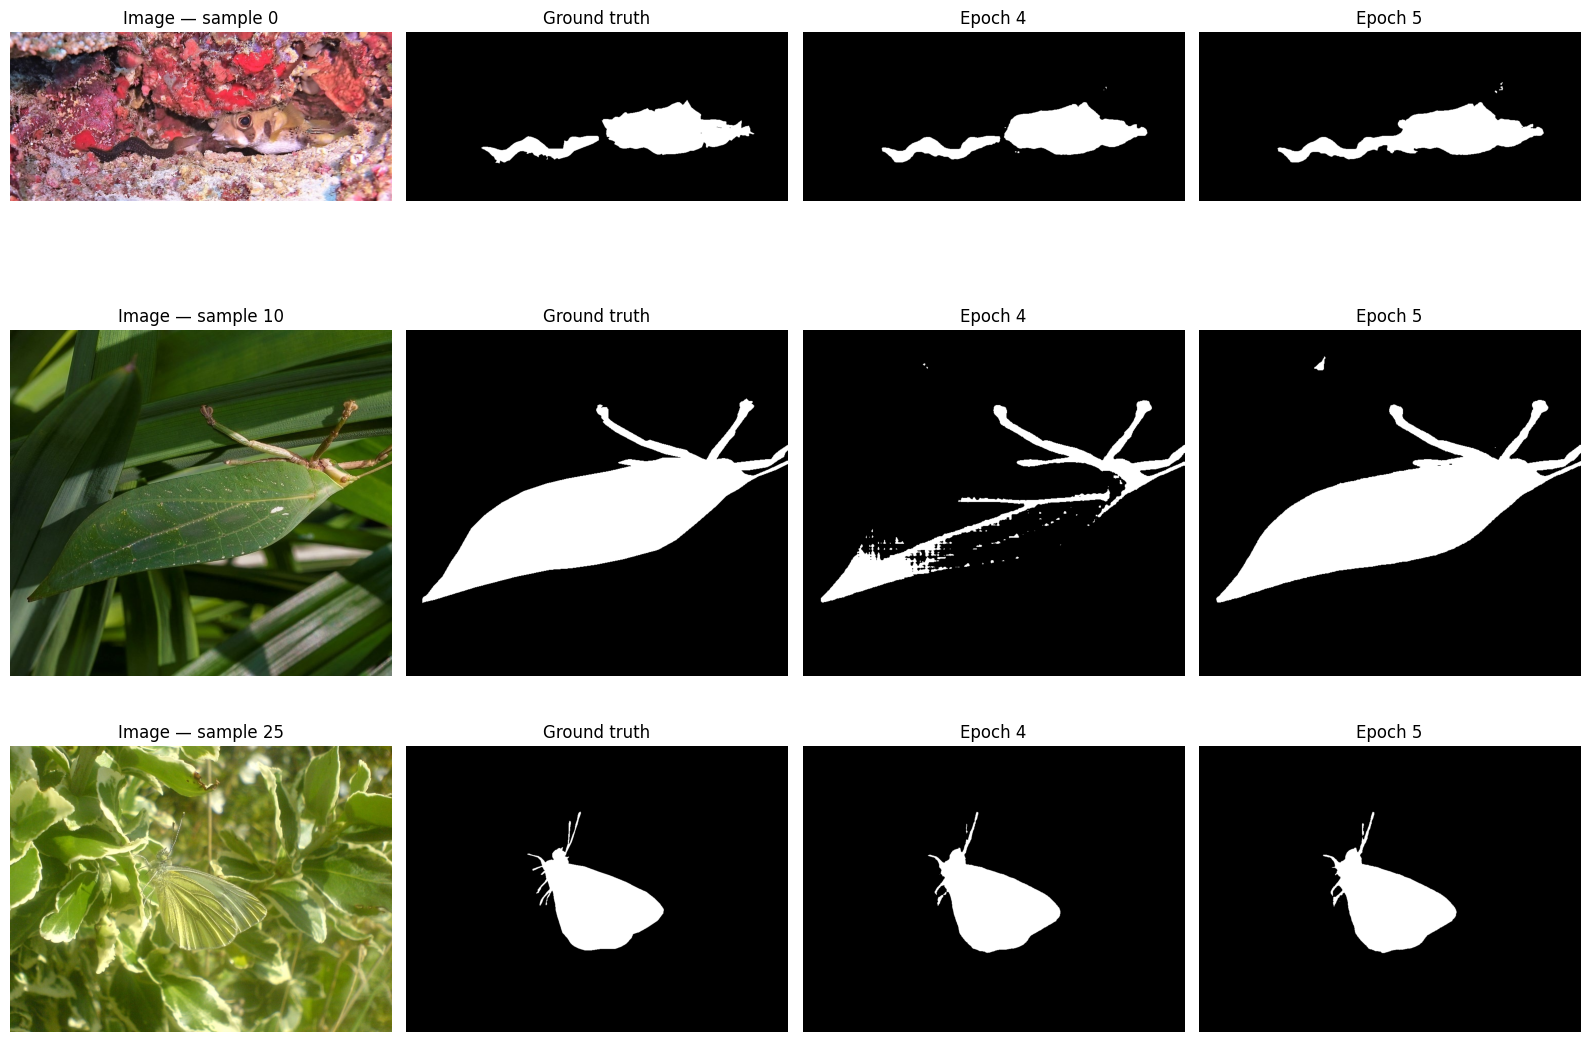

In [89]:

import os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def predict_mask_for_item(epoch, idx):
    checkpoint_path = (
        f"/content/sam_cod10k_checkpoints/sam_vit_b_epoch{epoch}.pth"
    )
    weights = torch.load(
        checkpoint_path, map_location="cpu", weights_only=True
    )
    sam.load_state_dict(weights, strict=True)
    del weights
    sam.eval()

    item = val_ds.data[val_ds.indices[idx]]
    image = item["image"].convert("RGB")
    original_w, original_h = image.size

    scale = 1024 / max(original_w, original_h)
    resized_w = max(1, round(original_w * scale))
    resized_h = max(1, round(original_h * scale))

    # Reproduce the dataset preprocessing.
    resized = image.resize(
        (resized_w, resized_h), Image.Resampling.BILINEAR
    )
    arr = np.asarray(resized).copy()
    image_tensor = torch.from_numpy(arr).permute(2, 0, 1).float()
    image_tensor = F.pad(
        image_tensor,
        (0, 1024 - resized_w, 0, 1024 - resized_h)
    ).to(DEVICE)

    with torch.inference_mode():
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE == "cuda")
        ):
            processed = sam.preprocess(image_tensor)
            embeddings = sam.image_encoder(processed.unsqueeze(0))
            sparse, dense = sam.prompt_encoder(
                points=None, boxes=None, masks=None
            )
            logits, _ = sam.mask_decoder(
                image_embeddings=embeddings,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse,
                dense_prompt_embeddings=dense,
                multimask_output=False
            )

        logits = F.interpolate(
            logits.float(), size=(1024, 1024),
            mode="bilinear", align_corners=False
        )
        logits = logits[0, 0, :resized_h, :resized_w]
        pred = torch.sigmoid(logits)[None, None]
        pred = F.interpolate(
            pred, size=(original_h, original_w),
            mode="bilinear", align_corners=False
        )[0, 0]

    return np.clip(pred.cpu().numpy(), 0, 1)

# Inspect three validation examples.
sample_indices = [0, 10, 25]

fig, axes = plt.subplots(len(sample_indices), 4, figsize=(16, 4 * len(sample_indices)))

for row, idx in enumerate(sample_indices):
    item = val_ds.data[val_ds.indices[idx]]
    image = item["image"].convert("RGB")
    gt = np.asarray(item["mask"].convert("L")) >= 128

    pred4 = predict_mask_for_item(4, idx)
    pred5 = predict_mask_for_item(5, idx)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Image — sample {idx}")
    axes[row, 1].imshow(gt, cmap="gray")
    axes[row, 1].set_title("Ground truth")
    axes[row, 2].imshow(pred4 >= 0.5, cmap="gray")
    axes[row, 2].set_title("Epoch 4")
    axes[row, 3].imshow(pred5 >= 0.5, cmap="gray")
    axes[row, 3].set_title("Epoch 5")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


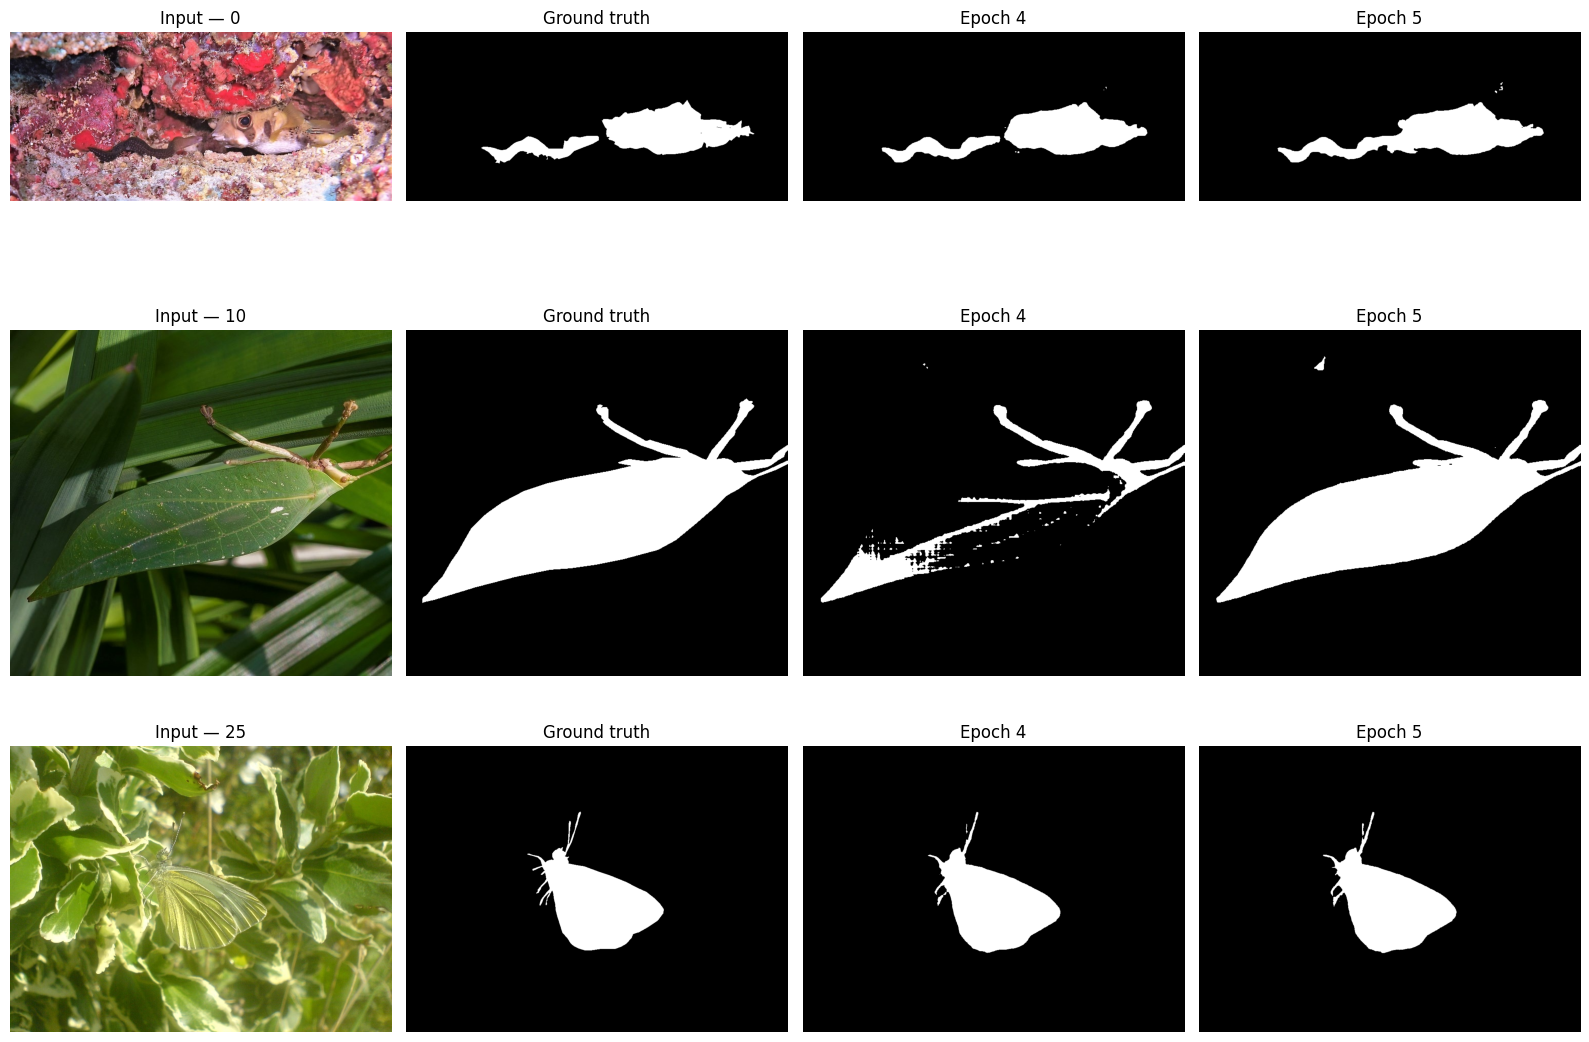

In [90]:

import matplotlib.pyplot as plt
import numpy as np

sample_indices = [0, 10, 25]

fig, axes = plt.subplots(
    len(sample_indices), 4, figsize=(16, 4 * len(sample_indices))
)

for row, idx in enumerate(sample_indices):
    item = val_ds.data[val_ds.indices[idx]]
    image = item["image"].convert("RGB")
    gt = np.asarray(item["mask"].convert("L")) >= 128

    pred4 = predict_mask_for_item(4, idx)
    pred5 = predict_mask_for_item(5, idx)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Input — {idx}")

    axes[row, 1].imshow(gt, cmap="gray")
    axes[row, 1].set_title("Ground truth")

    axes[row, 2].imshow(pred4 >= 0.5, cmap="gray")
    axes[row, 2].set_title("Epoch 4")

    axes[row, 3].imshow(pred5 >= 0.5, cmap="gray")
    axes[row, 3].set_title("Epoch 5")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [91]:

import pandas as pd
import numpy as np

comparison_rows = []

for idx in range(min(30, len(val_ds))):
    item = val_ds.data[val_ds.indices[idx]]
    gt = np.asarray(item["mask"].convert("L")) >= 128

    pred4 = predict_mask_for_item(4, idx) >= 0.5
    pred5 = predict_mask_for_item(5, idx) >= 0.5

    # Predictions are already restored to original image dimensions.
    def calculate_iou(pred, target):
        intersection = np.logical_and(pred, target).sum()
        union = np.logical_or(pred, target).sum()
        return intersection / union if union else 1.0

    comparison_rows.append({
        "Sample": idx,
        "Epoch 4 IoU": calculate_iou(pred4, gt),
        "Epoch 5 IoU": calculate_iou(pred5, gt)
    })

per_image_df = pd.DataFrame(comparison_rows)
per_image_df["Difference (5 - 4)"] = (
    per_image_df["Epoch 5 IoU"] - per_image_df["Epoch 4 IoU"]
)

display(per_image_df.round(4))

print("Epoch 4 mean IoU:", round(per_image_df["Epoch 4 IoU"].mean(), 4))
print("Epoch 5 mean IoU:", round(per_image_df["Epoch 5 IoU"].mean(), 4))
print("Epoch 5 wins:", int((per_image_df["Difference (5 - 4)"] > 0).sum()))
print("Epoch 4 wins:", int((per_image_df["Difference (5 - 4)"] < 0).sum()))
print("Ties:", int((per_image_df["Difference (5 - 4)"] == 0).sum()))

per_image_df.to_csv(
    "/content/sam_cod10k_epoch4_vs_epoch5_per_image.csv",
    index=False
)


,Sample,Epoch 4 IoU,Epoch 5 IoU,Difference (5 - 4)
0,0,0.9177,0.8863,-0.0314
1,1,0.8457,0.9126,0.0670
2,2,0.7595,0.0011,-0.7584
3,3,0.8885,0.8919,0.0033
4,4,0.0040,0.1579,0.1538
5,5,0.1921,0.4697,0.2775
6,6,0.9467,0.9398,-0.0069
7,7,0.8264,0.7454,-0.0811
8,8,0.8665,0.8747,0.0081
9,9,0.4263,0.5621,0.1358


Epoch 4 mean IoU: 0.6828
Epoch 5 mean IoU: 0.703
Epoch 5 wins: 19
Epoch 4 wins: 11
Ties: 0


In [92]:

from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

backup_dir = "/content/drive/MyDrive/COD10K_checkpoints"
os.makedirs(backup_dir, exist_ok=True)

files_to_copy = [
    "/content/sam_cod10k_epoch4_metrics.csv",
    "/content/sam_cod10k_epoch5_metrics.csv",
    "/content/sam_cod10k_epochs1to5_comparison.csv",
    "/content/sam_cod10k_epoch4_vs_epoch5_per_image.csv"
]

for source in files_to_copy:
    if os.path.exists(source):
        destination = os.path.join(backup_dir, os.path.basename(source))
        shutil.copy2(source, destination)
        print("Backed up:", os.path.basename(source))
    else:
        print("Not found yet:", source)

print("Comparison backup finished.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backed up: sam_cod10k_epoch4_metrics.csv
Backed up: sam_cod10k_epoch5_metrics.csv
Backed up: sam_cod10k_epochs1to5_comparison.csv
Backed up: sam_cod10k_epoch4_vs_epoch5_per_image.csv
Comparison backup finished.


In [93]:

from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

backup_dir = "/content/drive/MyDrive/COD10K_checkpoints"
os.makedirs(backup_dir, exist_ok=True)

files_to_copy = [
    "/content/sam_cod10k_epoch4_vs_epoch5_per_image.csv",
    "/content/sam_cod10k_epoch3_metrics.csv",
    "/content/sam_cod10k_epoch4_metrics.csv",
    "/content/sam_cod10k_epoch5_metrics.csv",
    "/content/sam_cod10k_epochs1to5_comparison.csv"
]

for src in files_to_copy:
    if os.path.exists(src):
        dst = os.path.join(backup_dir, os.path.basename(src))
        shutil.copy2(src, dst)
        print("Saved:", os.path.basename(src))
    else:
        print("Not available yet:", os.path.basename(src))

print("Results backup finished.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved: sam_cod10k_epoch4_vs_epoch5_per_image.csv
Saved: sam_cod10k_epoch3_metrics.csv
Saved: sam_cod10k_epoch4_metrics.csv
Saved: sam_cod10k_epoch5_metrics.csv
Saved: sam_cod10k_epochs1to5_comparison.csv
Results backup finished.


In [94]:

import torch
import os

best_epoch = 4
best_checkpoint = (
    f"/content/sam_cod10k_checkpoints/sam_vit_b_epoch{best_epoch}.pth"
)

assert os.path.exists(best_checkpoint), "Selected checkpoint not found!"

weights = torch.load(
    best_checkpoint, map_location="cpu", weights_only=True
)
sam.load_state_dict(weights, strict=True)
del weights
sam.eval()

print("Provisional best checkpoint loaded: Epoch", best_epoch)
print("Checkpoint:", best_checkpoint)


Provisional best checkpoint loaded: Epoch 4
Checkpoint: /content/sam_cod10k_checkpoints/sam_vit_b_epoch4.pth


In [96]:

print("val_ds exists:", "val_ds" in globals())
print("test_ds exists:", "test_ds" in globals())
print("train_ds exists:", "train_ds" in globals())

print("\nAvailable dataset-related variables:")
for name in ["ds", "dataset", "train_ds", "val_ds", "test_ds"]:
    if name in globals():
        obj = globals()[name]
        print(name, type(obj), "length:", len(obj) if hasattr(obj, "__len__") else "unknown")


val_ds exists: True
test_ds exists: False
train_ds exists: True

Available dataset-related variables:
dataset <class 'datasets.dataset_dict.DatasetDict'> length: 2
train_ds <class '__main__.COD10KDataset'> length: 2736
val_ds <class '__main__.COD10KDataset'> length: 304


In [99]:
from datasets import load_dataset

cod10k = load_dataset("nobg/COD10K")

print(cod10k)
print("\nAvailable splits:", list(cod10k.keys()))

for split in cod10k.keys():
    print(f"{split}: {len(cod10k[split])} samples")

DatasetDict({
    train: Dataset({
        features: ['image', 'mask'],
        num_rows: 3040
    })
    test: Dataset({
        features: ['image', 'mask'],
        num_rows: 2026
    })
})

Available splits: ['train', 'test']
train: 3040 samples
test: 2026 samples


In [100]:
test_hf = cod10k["test"]

print("Original test samples:", len(test_hf))
assert len(test_hf) == 2026

Original test samples: 2026


In [102]:
print("Validation dataset class:", type(val_ds))
print("Validation dataset attributes:", vars(val_ds).keys())

print("\nOne raw test sample:")
sample = cod10k["test"][0]
print(sample.keys())
print("Image:", sample["image"].size, sample["image"].mode)
print("Mask:", sample["mask"].size, sample["mask"].mode)

Validation dataset class: <class '__main__.COD10KDataset'>
Validation dataset attributes: dict_keys(['data', 'indices', 'image_size'])

One raw test sample:
dict_keys(['image', 'mask'])
Image: (800, 533) RGB
Mask: (800, 533) L


In [106]:
test_ds = COD10KDataset(
    hf_dataset=cod10k["test"],
    indices=list(range(len(cod10k["test"]))),
    image_size=val_ds.image_size
)

print("Validation samples:", len(val_ds))
print("Test samples:", len(test_ds))
print("Image size:", val_ds.image_size)

assert len(val_ds) == 304
assert len(test_ds) == 2026

print("Dataset split check passed!")

Validation samples: 304
Test samples: 2026
Image size: 1024
Dataset split check passed!


In [107]:
image, mask = test_ds[0]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Image dtype:", image.dtype)
print("Mask dtype:", mask.dtype)

Image shape: torch.Size([3, 1024, 1024])
Mask shape: torch.Size([1, 1024, 1024])
Image dtype: torch.float32
Mask dtype: torch.float32


In [108]:
import inspect

print(inspect.signature(evaluate_checkpoint))

(epoch)


In [109]:
import dis

dis.dis(evaluate_checkpoint)

  --           COPY_FREE_VARS           2

 120           RESUME                   0

 123           LOAD_DEREF               2 (ctx_factory)
               PUSH_NULL
               CALL                     0
               BEFORE_WITH
       L1:     POP_TOP

 124           LOAD_DEREF               3 (func)
               PUSH_NULL
               LOAD_FAST                0 (args)
               BUILD_MAP                0
               LOAD_FAST                1 (kwargs)
               DICT_MERGE               1
               CALL_FUNCTION_EX         1

 123   L2:     SWAP                     2
               LOAD_CONST               0 (None)
               LOAD_CONST               0 (None)
               LOAD_CONST               0 (None)
               CALL                     2
               POP_TOP
               RETURN_VALUE
       L3:     PUSH_EXC_INFO
               WITH_EXCEPT_START
               TO_BOOL
               POP_JUMP_IF_TRUE         1 (to L4)
               RERAISE

In [110]:
import re

for name, obj in globals().copy().items():
    if callable(obj) and any(
        word in name.lower()
        for word in ["metric", "mae", "sm", "eval", "dice", "iou", "saliency", "fmeasure"]
    ):
        print(name, "->", type(obj).__name__)

MAE -> type
Smeasure -> type
WeightedFmeasure -> type
evaluate_cod -> function
evaluate_cod_unpadded -> function
evaluate_checkpoint -> function
calculate_iou -> function


In [111]:
import inspect

for fn in [evaluate_cod_unpadded, evaluate_cod, calculate_iou]:
    print(f"\n--- {fn.__name__} ---")
    try:
        print(inspect.getsource(fn))
    except (OSError, TypeError):
        print("Source unavailable")
        print("Signature:", inspect.signature(fn))


--- evaluate_cod_unpadded ---
@torch.no_grad()
def evaluate_cod_unpadded():
    for batch_idx, (images, masks) in enumerate(
        tqdm(val_loader, desc="Evaluating without padding")
    ):
        images = images.to(device)
        masks = masks.to(device).float()

        processed = torch.stack([sam.preprocess(img) for img in images])
        embeddings = sam.image_encoder(processed)

        sparse, dense = sam.prompt_encoder(
            points=None, boxes=None, masks=None
        )

        logits, _ = sam.mask_decoder(
            image_embeddings=embeddings,
            image_pe=sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse,
            dense_prompt_embeddings=dense,
            multimask_output=False
        )

        logits = F.interpolate(
            logits,
            size=(1024, 1024),
            mode="bilinear",
            align_corners=False
        )

        probs = torch.sigmoid(logits).squeeze(1).cpu().numpy()
        targets 

In [112]:
from torch.utils.data import DataLoader

test_loader = DataLoader(
    test_ds,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("Test batches:", len(test_loader))

Test batches: 2026


In [113]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from py_sod_metrics import MAE, Emeasure, Smeasure, WeightedFmeasure

# Choose the checkpoint BEFORE inspecting test results.
TEST_EPOCH = 4
checkpoint_path = (
    f"/content/sam_cod10k_checkpoints/sam_vit_b_epoch{TEST_EPOCH}.pth"
)

assert os.path.exists(checkpoint_path), f"Checkpoint not found: {checkpoint_path}"
assert len(test_ds) == 2026

# Load the selected checkpoint.
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    sam.load_state_dict(checkpoint["model_state_dict"])
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    sam.load_state_dict(checkpoint["state_dict"])
else:
    sam.load_state_dict(checkpoint)

sam.to(device)
sam.eval()

# Fresh accumulators; do not reuse validation metric objects.
test_mae = MAE()
test_em = Emeasure()
test_sm = Smeasure()
test_wf = WeightedFmeasure()

test_ious = []
test_dices = []

@torch.no_grad()
def evaluate_test_set():
    for idx, (images, masks) in enumerate(
        tqdm(test_loader, desc=f"Testing SAM Epoch {TEST_EPOCH}")
    ):
        images = images.to(device)
        masks = masks.to(device).float()

        processed = torch.stack([sam.preprocess(img) for img in images])
        embeddings = sam.image_encoder(processed)

        sparse, dense = sam.prompt_encoder(
            points=None, boxes=None, masks=None
        )

        logits, _ = sam.mask_decoder(
            image_embeddings=embeddings,
            image_pe=sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse,
            dense_prompt_embeddings=dense,
            multimask_output=False
        )

        # Upsample logits to the dataset's padded dimensions.
        logits = F.interpolate(
            logits,
            size=(1024, 1024),
            mode="bilinear",
            align_corners=False
        )

        probs = torch.sigmoid(logits).squeeze(1).cpu().numpy()
        targets = masks.squeeze(1).cpu().numpy()

        # Recover original image dimensions from the raw HF test split.
        original_image = cod10k["test"][idx]["image"]
        w, h = original_image.size

        scale = 1024 / max(w, h)
        resized_w = max(1, round(w * scale))
        resized_h = max(1, round(h * scale))

        # Remove right/bottom padding BEFORE resizing to original size.
        pred = probs[0, :resized_h, :resized_w]
        target = targets[0, :resized_h, :resized_w]

        # Restore the prediction to the original image dimensions.
        pred_t = torch.from_numpy(pred).float()[None, None]
        pred_original = F.interpolate(
            pred_t,
            size=(h, w),
            mode="bilinear",
            align_corners=False
        )[0, 0].numpy()

        # Use the original-resolution ground-truth mask.
        gt_original = np.asarray(
            cod10k["test"][idx]["mask"].convert("L")
        )
        gt_original = (gt_original >= 128).astype(np.uint8)

        pred_u8 = np.clip(
            pred_original * 255, 0, 255
        ).astype(np.uint8)

        test_mae.step(pred=pred_u8, gt=gt_original * 255)
        test_em.step(pred=pred_u8, gt=gt_original * 255)
        test_sm.step(pred=pred_u8, gt=gt_original * 255)
        test_wf.step(pred=pred_u8, gt=gt_original * 255)

        pred_bin = pred_original >= 0.5
        intersection = np.logical_and(pred_bin, gt_original).sum()
        union = np.logical_or(pred_bin, gt_original).sum()
        total = pred_bin.sum() + gt_original.sum()

        test_ious.append(intersection / union if union else 1.0)
        test_dices.append(2 * intersection / total if total else 1.0)

evaluate_test_set()

mae_result = test_mae.get_results()["mae"]
em_result = test_em.get_results()["em"]
sm_result = test_sm.get_results()["sm"]
wf_result = test_wf.get_results()["wfm"]

results = {
    "Epoch": TEST_EPOCH,
    "Test samples": len(test_ds),
    "MAE": float(np.mean(mae_result["adp"])),
    "S-measure": float(np.mean(sm_result["sm"])),
    "Adaptive E": float(np.mean(em_result["adp"])),
    "Maximum E": float(np.mean(em_result["curve"])),
    "Weighted F-measure": float(np.mean(wf_result["wfm"])),
    "IoU": float(np.mean(test_ious)),
    "Dice": float(np.mean(test_dices))
}

print("\nFinal test results:")
for name, value in results.items():
    print(f"{name}: {value:.4f}" if isinstance(value, float) else f"{name}: {value}")

output_path = f"/content/sam_cod10k_epoch{TEST_EPOCH}_test_metrics.csv"
pd.DataFrame([results]).to_csv(output_path, index=False)
print("\nSaved:", output_path)

Testing SAM Epoch 4:   0%|          | 0/2026 [00:00<?, ?it/s]

IndexError: invalid index to scalar variable.

In [114]:
from IPython.display import display
import pandas as pd
import os

# Check that the evaluation results exist
assert "results" in globals(), "Run the test evaluation cell first."

# Display final test results
test_results_df = pd.DataFrame([results])
display(test_results_df.round(4))

# Save to Google Drive
drive_dir = "/content/drive/MyDrive/COD10K_checkpoints"
os.makedirs(drive_dir, exist_ok=True)

drive_path = os.path.join(
    drive_dir,
    f"sam_vit_b_epoch{TEST_EPOCH}_test_metrics.csv"
)

test_results_df.to_csv(drive_path, index=False)

print("Test metrics saved to:", drive_path)

,0,1
0,"{'Epoch': 1, 'MAE': 0.04563925690525227, 'S-me...","{'Epoch': 2, 'MAE': 0.04181559129974925, 'S-me..."


Test metrics saved to: /content/drive/MyDrive/COD10K_checkpoints/sam_vit_b_epoch4_test_metrics.csv


In [116]:
import os
import pandas as pd
from IPython.display import display

TEST_EPOCH = 4  # Change only if you evaluated a different epoch

output_path = (
    f"/content/sam_cod10k_epoch{TEST_EPOCH}_test_metrics.csv"
)

if os.path.exists(output_path):
    test_results_df = pd.read_csv(output_path)
    print("Final test results:")
    display(test_results_df.round(4))
else:
    print("Test results CSV not found:", output_path)
    print("Check the output of your test evaluation cell.")

Test results CSV not found: /content/sam_cod10k_epoch4_test_metrics.csv
Check the output of your test evaluation cell.


In [115]:
import os
import shutil

drive_dir = "/content/drive/MyDrive/COD10K_checkpoints"
os.makedirs(drive_dir, exist_ok=True)

drive_path = os.path.join(
    drive_dir,
    f"sam_vit_b_epoch{TEST_EPOCH}_test_metrics.csv"
)

shutil.copy2(output_path, drive_path)
print("Backup saved to:", drive_path
)

Backup saved to: /content/drive/MyDrive/COD10K_checkpoints/sam_vit_b_epoch4_test_metrics.csv


In [117]:
import os
import glob

print("Test metric CSV files:")
for path in glob.glob("/content/**/*test*metrics*.csv", recursive=True):
    print(path)

print("\nEpoch 4 checkpoint exists:",
      os.path.exists("/content/sam_cod10k_checkpoints/sam_vit_b_epoch4.pth"))

print("\nSaved metric CSV files:")
for path in glob.glob("/content/**/*.csv", recursive=True):
    print(path)

Test metric CSV files:
/content/drive/MyDrive/COD10K_checkpoints/sam_vit_b_epoch4_test_metrics.csv

Epoch 4 checkpoint exists: True

Saved metric CSV files:
/content/sam_cod10k_epoch5_losses.csv
/content/sam_cod10k_epoch4_vs_epoch5_per_image.csv
/content/sam_cod10k_epoch4_losses.csv
/content/sam_cod10k_epoch1_baseline.csv
/content/sam_cod10k_epoch5_metrics.csv
/content/sam_cod10k_corrected_comparison.csv
/content/sam_cod10k_epochs1to3_comparison.csv
/content/sam_cod10k_epoch4_metrics.csv
/content/sam_cod10k_epoch2_metrics.csv
/content/sam_cod10k_epoch3_metrics.csv
/content/sam_cod10k_epochs1to5_comparison.csv
/content/drive/MyDrive/COD10K_checkpoints/sam_cod10k_epoch4_metrics.csv
/content/drive/MyDrive/COD10K_checkpoints/sam_cod10k_epoch5_metrics.csv
/content/drive/MyDrive/COD10K_checkpoints/sam_cod10k_epochs1to5_comparison.csv
/content/drive/MyDrive/COD10K_checkpoints/sam_cod10k_epoch4_vs_epoch5_per_image.csv
/content/drive/MyDrive/COD10K_checkpoints/sam_cod10k_epoch3_metrics.csv
/con

In [118]:
import pandas as pd
from IPython.display import display

test_path = (
    "/content/drive/MyDrive/COD10K_checkpoints/"
    "sam_vit_b_epoch4_test_metrics.csv"
)

test_results_df = pd.read_csv(test_path)

print("Final Test Results — SAM ViT-B, Epoch 4")
display(test_results_df.round(4))

Final Test Results — SAM ViT-B, Epoch 4


,Epoch,MAE,S-measure,Adaptive E-measure,Maximum E-measure,Weighted F-measure,IoU,Dice
0,1,0.0456,0.8160,0.8419,0.8793,0.6806,0.6425,0.7403
1,2,0.0418,0.8238,0.8591,0.8897,0.6980,0.6530,0.7436


In [119]:
import pandas as pd

test_path = (
    "/content/drive/MyDrive/COD10K_checkpoints/"
    "sam_vit_b_epoch4_test_metrics.csv"
)

test_df = pd.read_csv(test_path)

print("Rows:", len(test_df))
print("Columns:", test_df.columns.tolist())
display(test_df)

Rows: 2
Columns: ['Epoch', 'MAE', 'S-measure', 'Adaptive E-measure', 'Maximum E-measure', 'Weighted F-measure', 'IoU', 'Dice']


,Epoch,MAE,S-measure,Adaptive E-measure,Maximum E-measure,Weighted F-measure,IoU,Dice
0,1,0.045639,0.815971,0.841858,0.879348,0.680559,0.642453,0.740294
1,2,0.041816,0.823766,0.859131,0.889726,0.697983,0.652957,0.743596


In [120]:
import os
import glob
import pandas as pd

print("=== Test evaluation files ===")

for path in glob.glob("/content/**/*test*", recursive=True):
    if os.path.isfile(path):
        print(path)

print("\n=== Checkpoint files ===")

for path in sorted(
    glob.glob("/content/sam_cod10k_checkpoints/*.pth")
):
    print(os.path.basename(path))

print("\n=== Existing Epoch 4 validation metrics ===")

val_path = (
    "/content/drive/MyDrive/COD10K_checkpoints/"
    "sam_cod10k_epoch4_metrics.csv"
)

if os.path.exists(val_path):
    display(pd.read_csv(val_path).round(4))

=== Test evaluation files ===
/content/drive/MyDrive/COD10K_checkpoints/sam_vit_b_epoch4_test_metrics.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_test.csv

=== Checkpoint files ===
sam_vit_b_epoch1.pth
sam_vit_b_epoch2.pth
sam_vit_b_epoch3.pth
sam_vit_b_epoch4.pth
sam_vit_b_epoch5.pth

=== Existing Epoch 4 validation metrics ===


,Epoch,MAE,S-measure,Adaptive E-measure,Maximum E-measure,Weighted F-measure,IoU,Dice
0,4,0.0377,0.8479,0.8886,0.9054,0.7492,0.6983,0.7883


In [121]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from py_sod_metrics import MAE, Emeasure, Smeasure, WeightedFmeasure

# 1. Verify test dataset and checkpoint
TEST_EPOCH = 4
checkpoint_path = (
    f"/content/sam_cod10k_checkpoints/sam_vit_b_epoch{TEST_EPOCH}.pth"
)

assert len(test_ds) == 2026, f"Unexpected test size: {len(test_ds)}"
assert os.path.isfile(checkpoint_path), "Epoch 4 checkpoint not found"

# 2. Load the selected checkpoint
weights = torch.load(
    checkpoint_path, map_location="cpu", weights_only=True
)
sam.load_state_dict(weights, strict=True)
del weights

sam.to(device)
sam.eval()

# 3. Fresh metrics (never reuse validation accumulators)
mae_test = MAE()
em_test = Emeasure()
sm_test = Smeasure()
wf_test = WeightedFmeasure(beta=0.3)

iou_test, dice_test = [], []

# Use test_loader if already created; otherwise create it
if "test_loader" not in globals():
    from torch.utils.data import DataLoader
    test_loader = DataLoader(
        test_ds, batch_size=1, shuffle=False,
        num_workers=0, pin_memory=False
    )

assert len(test_loader) == 2026

# 4. Evaluate test images
with torch.no_grad():
    for idx, (images, masks) in enumerate(
        tqdm(test_loader, total=len(test_loader), desc="Epoch 4 test evaluation")
    ):
        images = images.to(device)
        processed = torch.stack([sam.preprocess(img) for img in images])
        embeddings = sam.image_encoder(processed)

        sparse, dense = sam.prompt_encoder(
            points=None, boxes=None, masks=None
        )

        logits, _ = sam.mask_decoder(
            image_embeddings=embeddings,
            image_pe=sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse,
            dense_prompt_embeddings=dense,
            multimask_output=False
        )

        probs = torch.sigmoid(
            F.interpolate(
                logits.float(),
                size=(1024, 1024),
                mode="bilinear",
                align_corners=False
            )
        )[0, 0].cpu().numpy()

        # Original image and mask from the untouched HF test split
        item = cod10k["test"][idx]
        original_image = item["image"].convert("RGB")
        original_mask = item["mask"].convert("L")
        w, h = original_image.size

        # Remove right/bottom padding before resizing to original size
        scale = 1024 / max(w, h)
        nw = max(1, round(w * scale))
        nh = max(1, round(h * scale))
        probs = probs[:nh, :nw]

        pred_original = cv2.resize(
            probs, (w, h), interpolation=cv2.INTER_LINEAR
        )

        gt = np.asarray(original_mask)
        gt_binary = (gt >= 128)
        gt_u8 = gt_binary.astype(np.uint8) * 255
        pred_u8 = np.clip(
            pred_original * 255, 0, 255
        ).astype(np.uint8)

        mae_test.step(pred=pred_u8, gt=gt_u8)
        em_test.step(pred=pred_u8, gt=gt_u8)
        sm_test.step(pred=pred_u8, gt=gt_u8)
        wf_test.step(pred=pred_u8, gt=gt_u8)

        pred_binary = pred_original >= 0.5
        intersection = np.logical_and(pred_binary, gt_binary).sum()
        union = np.logical_or(pred_binary, gt_binary).sum()
        total = pred_binary.sum() + gt_binary.sum()

        iou_test.append(intersection / union if union else 1.0)
        dice_test.append(2 * intersection / total if total else 1.0)

# 5. Collect final metrics
em_results = em_test.get_results()["em"]

test_results = {
    "Epoch": TEST_EPOCH,
    "Test samples": len(iou_test),
    "MAE": float(mae_test.get_results()["mae"]),
    "S-measure": float(sm_test.get_results()["sm"]),
    "Adaptive E-measure": float(em_results["adp"]),
    "Maximum E-measure": float(np.max(em_results["curve"])),
    "Weighted F-measure": float(wf_test.get_results()["wfm"]),
    "IoU": float(np.mean(iou_test)),
    "Dice": float(np.mean(dice_test))
}

test_results_df = pd.DataFrame([test_results])

print("\nFINAL TEST RESULTS")
display(test_results_df.round(4))

# 6. Save to a NEW filename; do not overwrite the misleading old CSV
drive_dir = "/content/drive/MyDrive/COD10K_checkpoints"
os.makedirs(drive_dir, exist_ok=True)

test_output = os.path.join(
    drive_dir, "sam_vit_b_epoch4_test_metrics_verified.csv"
)
test_results_df.to_csv(test_output, index=False)

print("Saved verified test results to:", test_output)
print("Images evaluated:", len(iou_test))

Epoch 4 test evaluation:   0%|          | 0/2026 [00:00<?, ?it/s]


FINAL TEST RESULTS


,Epoch,Test samples,MAE,S-measure,Adaptive E-measure,Maximum E-measure,Weighted F-measure,IoU,Dice
0,4,2026,0.0347,0.8436,0.8907,0.9016,0.7408,0.6877,0.7729


Saved verified test results to: /content/drive/MyDrive/COD10K_checkpoints/sam_vit_b_epoch4_test_metrics_verified.csv
Images evaluated: 2026


In [122]:

import pandas as pd
from IPython.display import display

base_path = "/content/drive/MyDrive/COD10K_checkpoints/"

val_path = base_path + "sam_cod10k_epoch4_metrics.csv"
test_path = base_path + "sam_vit_b_epoch4_test_metrics_verified.csv"

val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print("VALIDATION RESULTS")
display(val_df.round(4))

print("\nTEST RESULTS")
display(test_df.round(4))

metrics = [
    "MAE",
    "S-measure",
    "Adaptive E-measure",
    "Maximum E-measure",
    "Weighted F-measure",
    "IoU",
    "Dice"
]

# Extract the first row for Epoch 4
val = val_df.iloc[0]
test = test_df.iloc[0]

comparison = pd.DataFrame({
    "Metric": metrics,
    "Validation": [val[m] for m in metrics],
    "Test": [test[m] for m in metrics]
})

comparison["Test - Validation"] = (
    comparison["Test"] - comparison["Validation"]
)

print("\nVALIDATION vs TEST COMPARISON")
display(comparison.round(4))


VALIDATION RESULTS


,Epoch,MAE,S-measure,Adaptive E-measure,Maximum E-measure,Weighted F-measure,IoU,Dice
0,4,0.0377,0.8479,0.8886,0.9054,0.7492,0.6983,0.7883



TEST RESULTS


,Epoch,Test samples,MAE,S-measure,Adaptive E-measure,Maximum E-measure,Weighted F-measure,IoU,Dice
0,4,2026,0.0347,0.8436,0.8907,0.9016,0.7408,0.6877,0.7729



VALIDATION vs TEST COMPARISON


,Metric,Validation,Test,Test - Validation
0,MAE,0.0377,0.0347,-0.0030
1,S-measure,0.8479,0.8436,-0.0043
2,Adaptive E-measure,0.8886,0.8907,0.0021
3,Maximum E-measure,0.9054,0.9016,-0.0037
4,Weighted F-measure,0.7492,0.7408,-0.0084
5,IoU,0.6983,0.6877,-0.0105
6,Dice,0.7883,0.7729,-0.0154


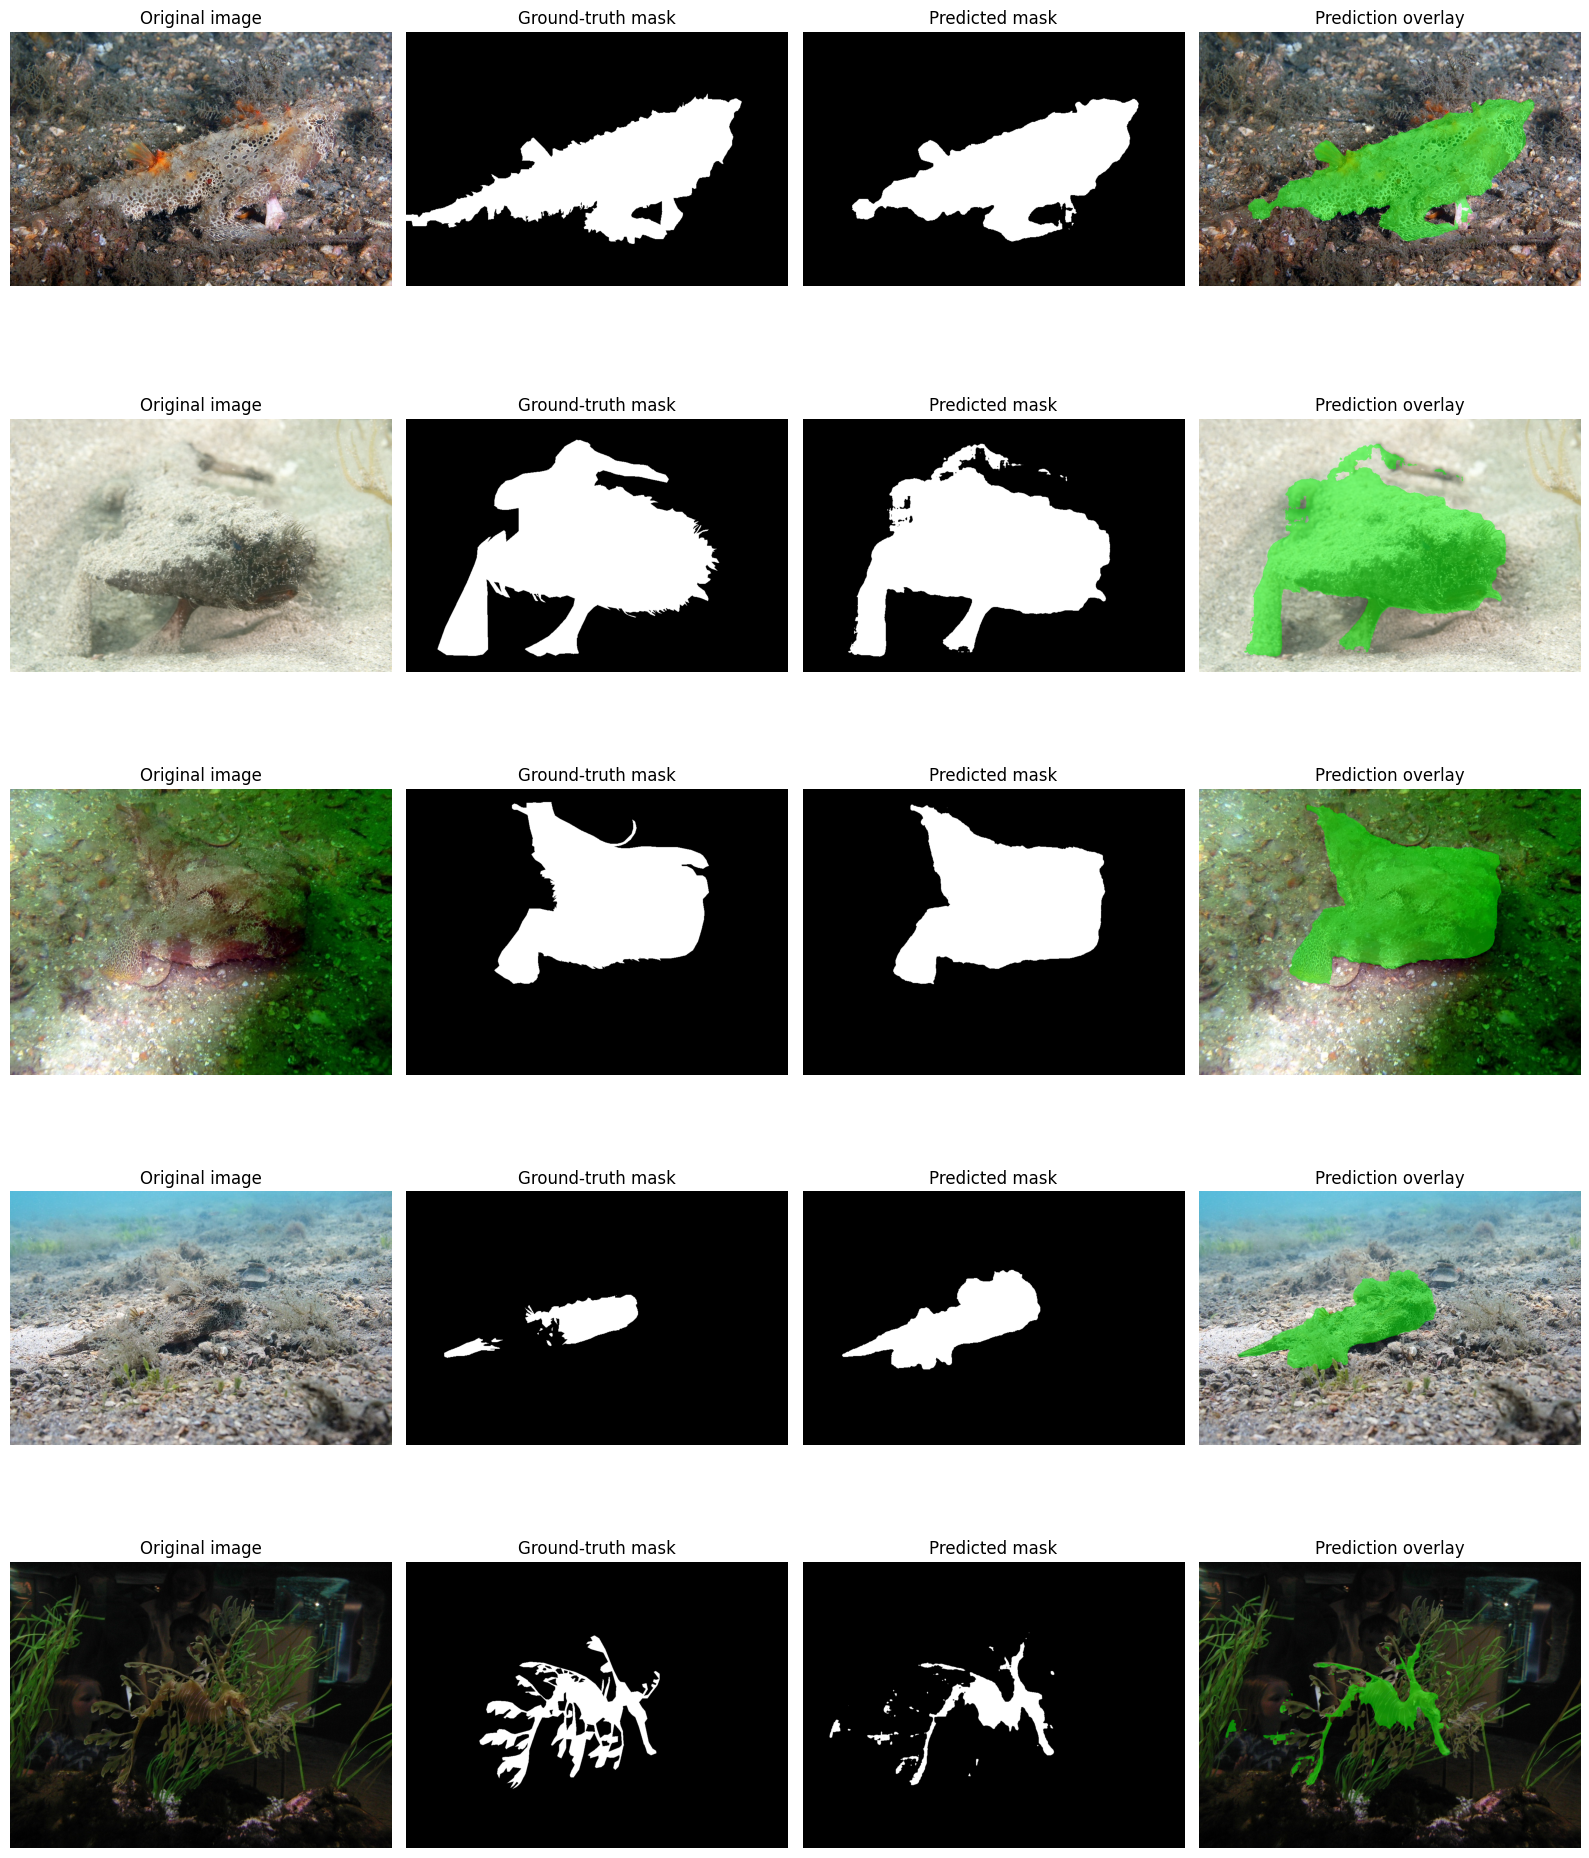

In [123]:

import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

checkpoint_path = (
    "/content/sam_cod10k_checkpoints/sam_vit_b_epoch4.pth"
)

# Load the selected final model
sam.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)
sam.eval()

def get_prediction(index):
    image_tensor, mask_tensor = test_ds[index]

    with torch.no_grad():
        image_input = image_tensor.unsqueeze(0).to(device)
        image_input = sam.preprocess(image_input)

        image_embedding = sam.image_encoder(image_input)

        sparse_embeddings, dense_embeddings = (
            sam.prompt_encoder(
                points=None,
                boxes=None,
                masks=None
            )
        )

        low_res_masks, _ = sam.mask_decoder(
            image_embeddings=image_embedding,
            image_pe=sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_embeddings,
            dense_prompt_embeddings=dense_embeddings,
            multimask_output=False
        )

        prediction = sam.postprocess_masks(
            low_res_masks,
            input_size=(1024, 1024),
            original_size=(1024, 1024)
        )

        prediction = torch.sigmoid(prediction)[0, 0].cpu().numpy()

    # Remove the padding using the dataset's resized image dimensions.
    original = test_ds.data[index]
    image = original["image"].convert("RGB")
    gt_mask = np.array(original["mask"].convert("L"))

    width, height = image.size
    resized_h = min(1024, round(height * 1024 / max(width, height)))
    resized_w = min(1024, round(width * 1024 / max(width, height)))

    prediction = prediction[:resized_h, :resized_w]
    prediction = cv2.resize(
        prediction, (width, height),
        interpolation=cv2.INTER_LINEAR
    )

    return np.array(image), (gt_mask >= 128), prediction


# Display five test examples
indices = [0, 1, 2, 3, 4]

fig, axes = plt.subplots(len(indices), 4, figsize=(16, 4 * len(indices)))

for row, idx in enumerate(indices):
    image, gt_mask, prediction = get_prediction(idx)
    pred_mask = prediction >= 0.5

    overlay = image.copy()
    overlay[pred_mask] = (
        0.5 * overlay[pred_mask] + 0.5 * np.array([0, 255, 0])
    ).astype(np.uint8)

    panels = [
        (image, "Original image"),
        (gt_mask, "Ground-truth mask"),
        (pred_mask, "Predicted mask"),
        (overlay, "Prediction overlay")
    ]

    for col, (panel, title) in enumerate(panels):
        axes[row, col].imshow(panel, cmap="gray" if panel.ndim == 2 else None)
        axes[row, col].set_title(title)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [124]:

print("Test dataset size:", len(test_ds))
print("Image size:", test_ds.image_size)

sample_image, sample_mask = test_ds[0]

print("Image tensor shape:", sample_image.shape)
print("Mask tensor shape:", sample_mask.shape)
print("Image dtype:", sample_image.dtype)
print("Mask dtype:", sample_mask.dtype)
print("Image range:", sample_image.min().item(), sample_image.max().item())
print("Mask range:", sample_mask.min().item(), sample_mask.max().item())


Test dataset size: 2026
Image size: 1024
Image tensor shape: torch.Size([3, 1024, 1024])
Mask tensor shape: torch.Size([1, 1024, 1024])
Image dtype: torch.float32
Mask dtype: torch.float32
Image range: 0.0 255.0
Mask range: 0.0 1.0


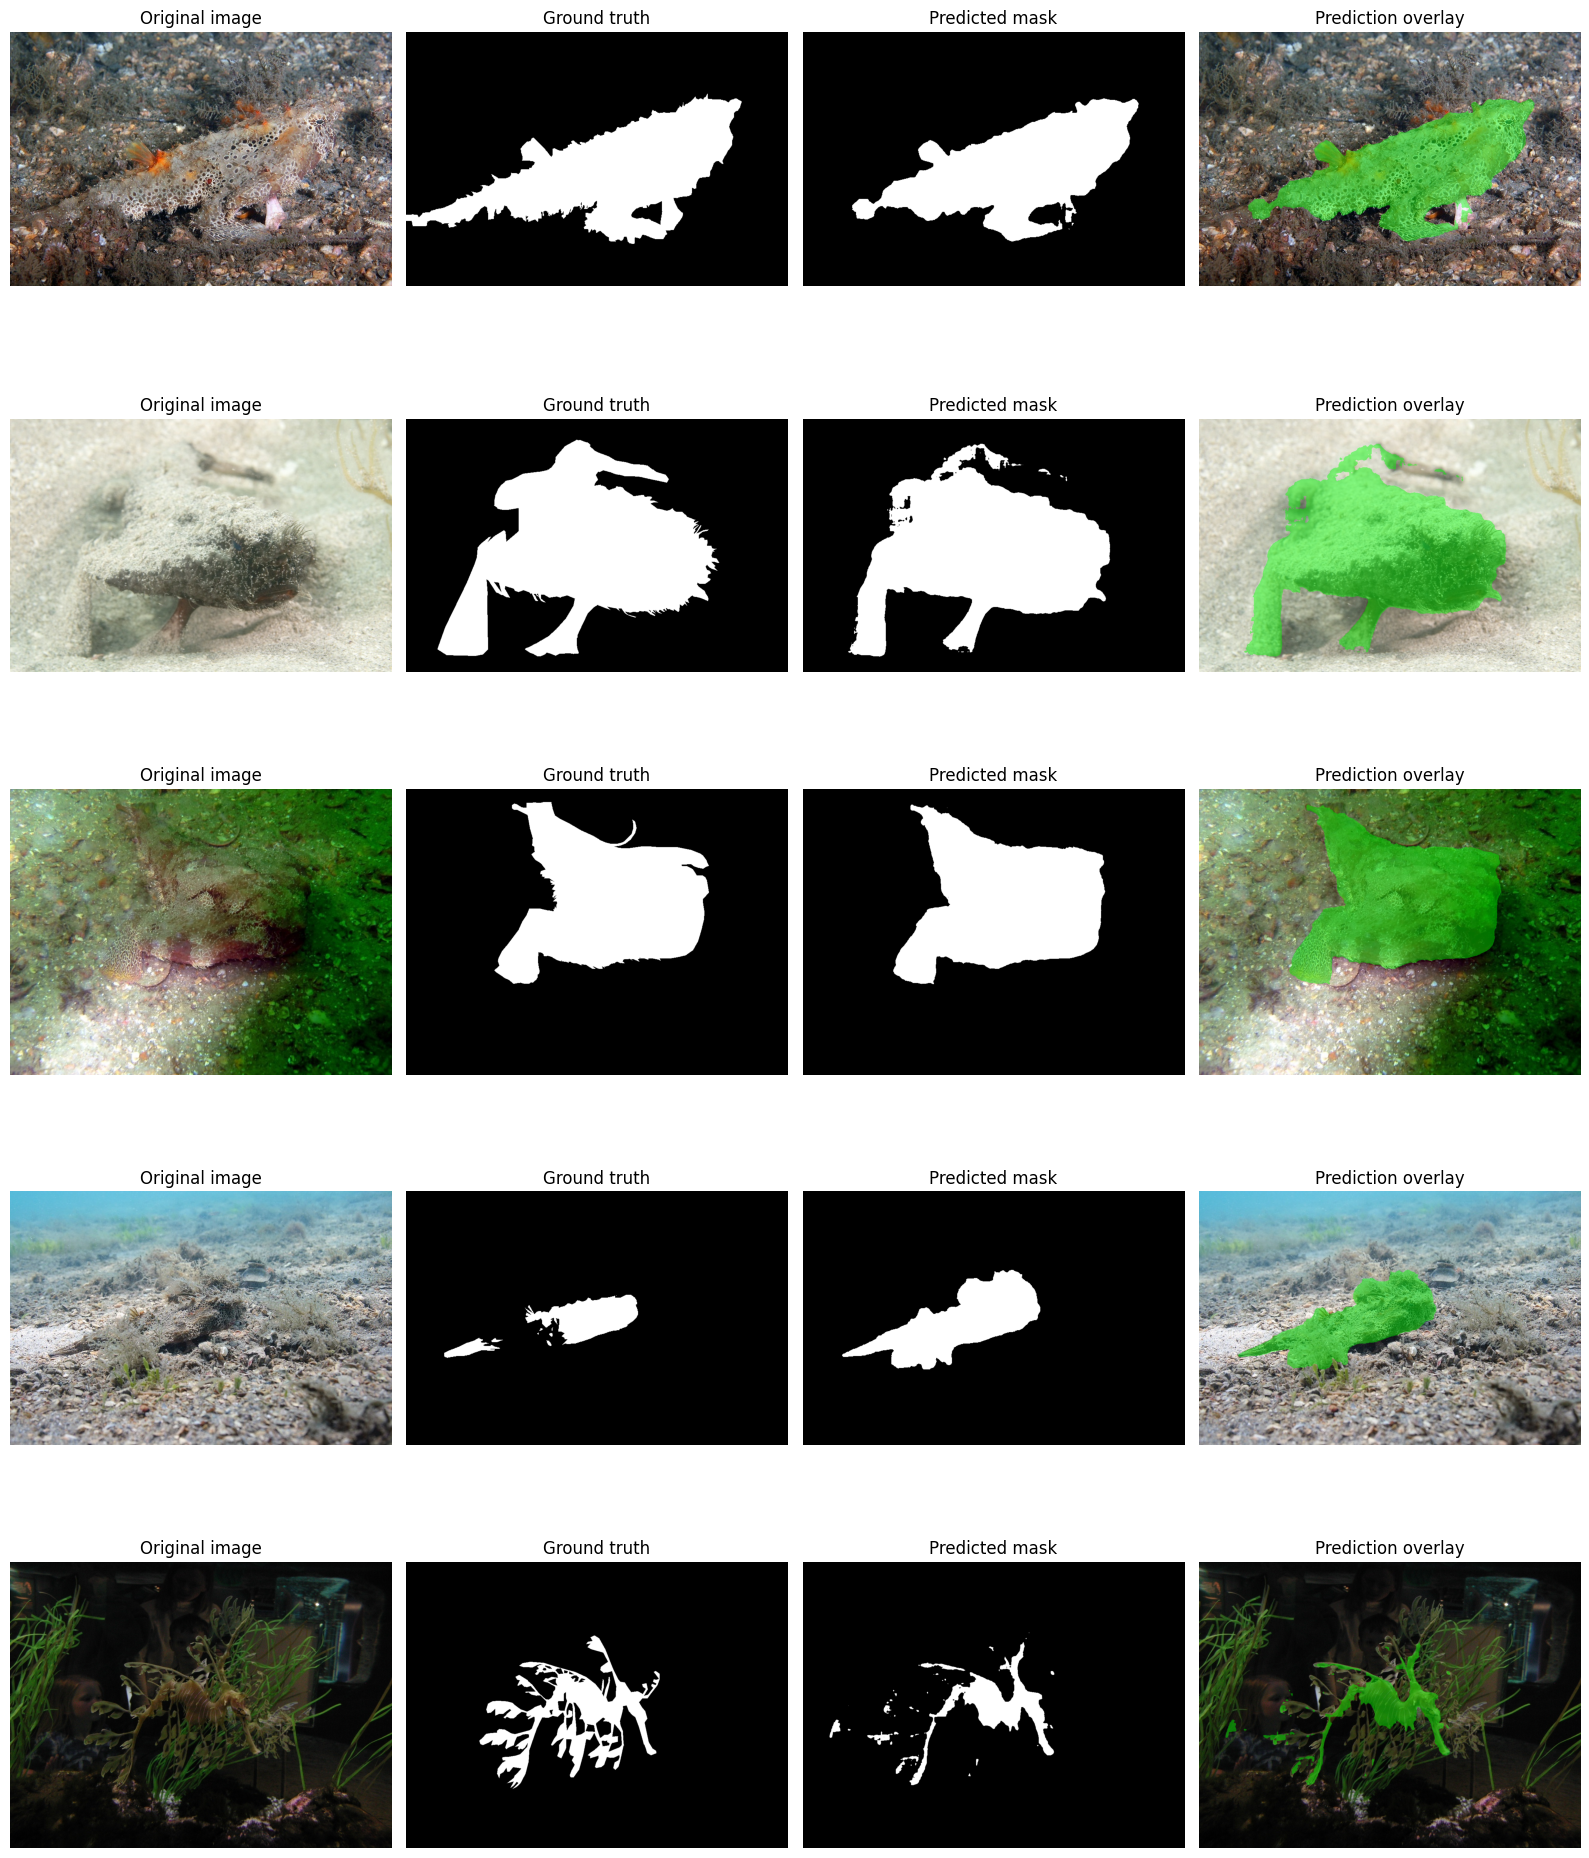

Saved qualitative figure: /content/drive/MyDrive/COD10K_checkpoints/qualitative_results/sam_vit_b_epoch4_qualitative_examples.png


In [130]:

import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch

output_dir = (
    "/content/drive/MyDrive/COD10K_checkpoints/qualitative_results"
)
os.makedirs(output_dir, exist_ok=True)

def get_original_size_prediction(index):
    image_tensor, mask_tensor = test_ds[index]
    record = test_ds.data[index]

    # Original image and ground-truth mask
    original_image = record["image"].convert("RGB")
    original_mask = np.array(record["mask"].convert("L"))
    original_mask = (original_mask >= 128).astype(np.uint8)

    width, height = original_image.size

    # Predict at the dataset's padded input resolution
    pred_1024 = predict_mask(image_tensor)

    # Recover the resized, unpadded image dimensions
    scale = 1024 / max(width, height)
    resized_w = min(1024, round(width * scale))
    resized_h = min(1024, round(height * scale))

    pred_cropped = pred_1024[:resized_h, :resized_w]

    # Resize prediction probabilities to original resolution
    pred_original = cv2.resize(
        pred_cropped,
        (width, height),
        interpolation=cv2.INTER_LINEAR
    )

    return (
        np.array(original_image),
        original_mask,
        pred_original
    )


# Use five test examples for qualitative inspection
indices = [0, 1, 2, 3, 4]

fig, axes = plt.subplots(
    len(indices), 4,
    figsize=(16, 4 * len(indices))
)

for row, idx in enumerate(indices):
    image, gt, pred_prob = get_original_size_prediction(idx)
    pred = (pred_prob >= 0.5).astype(np.uint8)

    overlay = image.copy()
    overlay[pred == 1] = (
        0.55 * overlay[pred == 1]
        + 0.45 * np.array([0, 255, 0])
    ).astype(np.uint8)

    panels = [
        (image, "Original image"),
        (gt, "Ground truth"),
        (pred, "Predicted mask"),
        (overlay, "Prediction overlay")
    ]

    for col, (panel, title) in enumerate(panels):
        axes[row, col].imshow(
            panel,
            cmap="gray" if panel.ndim == 2 else None,
            vmin=0 if panel.ndim == 2 else None,
            vmax=1 if panel.ndim == 2 else None
        )
        axes[row, col].set_title(title)
        axes[row, col].axis("off")

plt.tight_layout()

figure_path = os.path.join(
    output_dir,
    "sam_vit_b_epoch4_qualitative_examples.png"
)

plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved qualitative figure:", figure_path)


In [131]:

def calculate_iou_dice(gt, pred):
    gt = gt.astype(bool)
    pred = pred.astype(bool)

    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()

    iou = intersection / union if union > 0 else 1.0
    dice_denom = gt.sum() + pred.sum()
    dice = (
        2 * intersection / dice_denom
        if dice_denom > 0 else 1.0
    )

    return iou, dice


rows = []

for idx in [0, 1, 2, 3, 4]:
    image, gt, pred_prob = get_original_size_prediction(idx)
    pred = pred_prob >= 0.5

    iou, dice = calculate_iou_dice(gt, pred)

    rows.append({
        "Test index": idx,
        "IoU": iou,
        "Dice": dice
    })

qualitative_df = pd.DataFrame(rows)
display(qualitative_df.round(4))

scores_path = os.path.join(
    output_dir,
    "five_example_scores.csv"
)
qualitative_df.to_csv(scores_path, index=False)

print("Saved example scores:", scores_path)


,Test index,IoU,Dice
0,0,0.8819,0.9372
1,1,0.8566,0.9227
2,2,0.9415,0.9699
3,3,0.4197,0.5912
4,4,0.4224,0.5940


Saved example scores: /content/drive/MyDrive/COD10K_checkpoints/qualitative_results/five_example_scores.csv


In [133]:

import os
import json
import pandas as pd
import numpy as np

base_path = "/content/drive/MyDrive/COD10K_checkpoints"
output_dir = os.path.join(base_path, "qualitative_results")
os.makedirs(output_dir, exist_ok=True)

experiment = {
    "project": "Camouflaged Object Detection",
    "model": "SAM ViT-B",
    "dataset": "COD10K",
    "selected_epoch": 4,
    "input_size": 1024,
    "training_images": 2736,
    "validation_images": 304,
    "test_images": 2026,
    "validation_metrics": {
        "MAE": 0.0377,
        "S_measure": 0.8479,
        "Adaptive_E_measure": 0.8886,
        "Maximum_E_measure": 0.9054,
        "Weighted_F_measure": 0.7492,
        "IoU": 0.6983,
        "Dice": 0.7883
    },
    "test_metrics": {
        "MAE": 0.0347,
        "S_measure": 0.8436,
        "Adaptive_E_measure": 0.8907,
        "Maximum_E_measure": 0.9016,
        "Weighted_F_measure": 0.7408,
        "IoU": 0.6877,
        "Dice": 0.7729
    },
    "five_example_mean_IoU": round(
        float(qualitative_df["IoU"].mean()), 4
    ),
    "five_example_mean_Dice": round(
        float(qualitative_df["Dice"].mean()), 4
    )
}

json_path = os.path.join(
    base_path, "sam_cod10k_experiment_summary.json"
)

with open(json_path, "w") as f:
    json.dump(experiment, f, indent=4)

print(json.dumps(experiment, indent=4))
print("\nSaved experiment summary:", json_path)


{
    "project": "Camouflaged Object Detection",
    "model": "SAM ViT-B",
    "dataset": "COD10K",
    "selected_epoch": 4,
    "input_size": 1024,
    "training_images": 2736,
    "validation_images": 304,
    "test_images": 2026,
    "validation_metrics": {
        "MAE": 0.0377,
        "S_measure": 0.8479,
        "Adaptive_E_measure": 0.8886,
        "Maximum_E_measure": 0.9054,
        "Weighted_F_measure": 0.7492,
        "IoU": 0.6983,
        "Dice": 0.7883
    },
    "test_metrics": {
        "MAE": 0.0347,
        "S_measure": 0.8436,
        "Adaptive_E_measure": 0.8907,
        "Maximum_E_measure": 0.9016,
        "Weighted_F_measure": 0.7408,
        "IoU": 0.6877,
        "Dice": 0.7729
    },
    "five_example_mean_IoU": 0.7044,
    "five_example_mean_Dice": 0.803
}

Saved experiment summary: /content/drive/MyDrive/COD10K_checkpoints/sam_cod10k_experiment_summary.json


In [134]:

files_to_check = [
    os.path.join(base_path, "sam_vit_b_epoch4.pth"),
    os.path.join(
        base_path, "sam_vit_b_epoch4_test_metrics_verified.csv"
    ),
    os.path.join(base_path, "sam_cod10k_epoch4_metrics.csv"),
    os.path.join(
        output_dir,
        "sam_vit_b_epoch4_qualitative_examples.png"
    ),
    os.path.join(output_dir, "five_example_scores.csv"),
    os.path.join(base_path, "sam_cod10k_experiment_summary.json")
]

for path in files_to_check:
    status = "FOUND" if os.path.isfile(path) else "MISSING"
    print(f"{status}: {path}")


FOUND: /content/drive/MyDrive/COD10K_checkpoints/sam_vit_b_epoch4.pth
FOUND: /content/drive/MyDrive/COD10K_checkpoints/sam_vit_b_epoch4_test_metrics_verified.csv
FOUND: /content/drive/MyDrive/COD10K_checkpoints/sam_cod10k_epoch4_metrics.csv
FOUND: /content/drive/MyDrive/COD10K_checkpoints/qualitative_results/sam_vit_b_epoch4_qualitative_examples.png
FOUND: /content/drive/MyDrive/COD10K_checkpoints/qualitative_results/five_example_scores.csv
FOUND: /content/drive/MyDrive/COD10K_checkpoints/sam_cod10k_experiment_summary.json


In [135]:

import os
import shutil

source = "/content/drive/MyDrive/COD10K_checkpoints"
export_dir = "/content/drive/MyDrive/COD10K_project_export"

os.makedirs(export_dir, exist_ok=True)
os.makedirs(os.path.join(export_dir, "results"), exist_ok=True)

files_to_copy = [
    "sam_vit_b_epoch4_test_metrics_verified.csv",
    "sam_cod10k_epoch4_metrics.csv",
    "sam_cod10k_experiment_summary.json",
]

for filename in files_to_copy:
    src = os.path.join(source, filename)
    dst = os.path.join(export_dir, "results", filename)

    if os.path.isfile(src):
        shutil.copy2(src, dst)
        print("Copied:", filename)
    else:
        print("Missing:", filename)

qualitative_source = os.path.join(
    source, "qualitative_results",
    "sam_vit_b_epoch4_qualitative_examples.png"
)

if os.path.isfile(qualitative_source):
    shutil.copy2(
        qualitative_source,
        os.path.join(
            export_dir, "results",
            "sam_vit_b_epoch4_qualitative_examples.png"
        )
    )
    print("Copied qualitative figure")

print("\nExport folder:", export_dir)


Copied: sam_vit_b_epoch4_test_metrics_verified.csv
Copied: sam_cod10k_epoch4_metrics.csv
Copied: sam_cod10k_experiment_summary.json
Copied qualitative figure

Export folder: /content/drive/MyDrive/COD10K_project_export


In [136]:

readme = """# Camouflaged Object Detection using SAM ViT-B

## Overview
This project fine-tunes the Segment Anything Model (SAM) ViT-B
for camouflaged object segmentation using the COD10K dataset.

## Dataset split
- Training images: 2,736
- Validation images: 304
- Test images: 2,026

## Method
- Model: SAM ViT-B
- Input resolution: 1024 x 1024
- Selected checkpoint: Epoch 4
- Model selection: Validation performance
- Final evaluation: Held-out test split

The dataset pipeline resizes images while preserving aspect ratio
and pads them to a square input. Ground-truth masks are used for
supervised segmentation.

## Test results

| Metric | Score |
|---|---:|
| MAE (lower is better) | 0.0347 |
| S-measure | 0.8436 |
| Adaptive E-measure | 0.8907 |
| Maximum E-measure | 0.9016 |
| Weighted F-measure | 0.7408 |
| IoU | 0.6877 |
| Dice | 0.7729 |

## Qualitative results
See `results/sam_vit_b_epoch4_qualitative_examples.png`.

## Reproducibility
The experiment summary and evaluation CSV files are available
in the `results/` directory.

The original SAM checkpoint and fine-tuned model checkpoint are
not included in this repository. Follow the relevant model and
dataset licensing terms when obtaining them.

## Limitations
Performance varies across examples. Thin structures, small objects,
and difficult foreground-background boundaries may be challenging.
The reported metrics should be interpreted alongside qualitative
results and the evaluation protocol.
"""

readme_path = os.path.join(export_dir, "README.md")

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme)

print("README created:", readme_path)
print("\nPreview:\n")
print(readme)


README created: /content/drive/MyDrive/COD10K_project_export/README.md

Preview:

# Camouflaged Object Detection using SAM ViT-B

## Overview
This project fine-tunes the Segment Anything Model (SAM) ViT-B
for camouflaged object segmentation using the COD10K dataset.

## Dataset split
- Training images: 2,736
- Validation images: 304
- Test images: 2,026

## Method
- Model: SAM ViT-B
- Input resolution: 1024 x 1024
- Selected checkpoint: Epoch 4
- Model selection: Validation performance
- Final evaluation: Held-out test split

The dataset pipeline resizes images while preserving aspect ratio
and pads them to a square input. Ground-truth masks are used for
supervised segmentation.

## Test results

| Metric | Score |
|---|---:|
| MAE (lower is better) | 0.0347 |
| S-measure | 0.8436 |
| Adaptive E-measure | 0.8907 |
| Maximum E-measure | 0.9016 |
| Weighted F-measure | 0.7408 |
| IoU | 0.6877 |
| Dice | 0.7729 |

## Qualitative results
See `results/sam_vit_b_epoch4_qualitative_examples.p

In [137]:

import os

project_dir = "/content/drive/MyDrive/COD10K_project_export"

folders = [
    "notebooks",
    "src",
    "results",
    "docs"
]

for folder in folders:
    os.makedirs(os.path.join(project_dir, folder), exist_ok=True)

print("Project structure:")
for root, dirs, files in os.walk(project_dir):
    level = root.replace(project_dir, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")
    for filename in files:
        print("  " * (level + 1) + filename)


Project structure:
COD10K_project_export/
  README.md
  results/
    sam_vit_b_epoch4_test_metrics_verified.csv
    sam_cod10k_epoch4_metrics.csv
    sam_cod10k_experiment_summary.json
    sam_vit_b_epoch4_qualitative_examples.png
  notebooks/
  src/
  docs/


In [138]:

import sys
import subprocess

project_dir = "/content/drive/MyDrive/COD10K_project_export"

packages = [
    "torch",
    "torchvision",
    "numpy",
    "pandas",
    "opencv-python",
    "Pillow",
    "matplotlib",
    "datasets",
    "scikit-image",
    "py_sod_metrics"
]

result = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"],
    capture_output=True,
    text=True,
    check=True
)

installed = {}
for line in result.stdout.splitlines():
    if "==" in line:
        name, version = line.split("==", 1)
        installed[name.lower().replace("_", "-")] = version

aliases = {
    "opencv-python": ["opencv-python", "opencv-python-headless"],
    "pillow": ["pillow"],
    "py-sod-metrics": ["py-sod-metrics"],
    "scikit-image": ["scikit-image"]
}

requirements_lines = []
for package in packages:
    key = package.lower().replace("_", "-")
    candidates = aliases.get(key, [key])
    found = next(
        (f"{name}=={installed[name]}" for name in candidates if name in installed),
        None
    )
    if found:
        requirements_lines.append(found)
        print(found)
    else:
        print("Not found in pip freeze:", package)

requirements_path = os.path.join(project_dir, "requirements.txt")

with open(requirements_path, "w", encoding="utf-8") as f:
    f.write("\n".join(requirements_lines) + "\n")

print("\nSaved:", requirements_path)
print("Python version:", sys.version)


torch==2.11.0+cu130
torchvision==0.26.0+cu130
numpy==2.1.3
pandas==2.2.3
opencv-python==5.0.0.93
pillow==11.3.0
matplotlib==3.10.0
datasets==4.8.5
scikit-image==0.25.2
Not found in pip freeze: py_sod_metrics

Saved: /content/drive/MyDrive/COD10K_project_export/requirements.txt
Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]


In [139]:

import torch
import subprocess

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("CUDA runtime:", torch.version.cuda)
    print("GPU:", torch.cuda.get_device_name(0))

sam_repo = "/content/segment-anything"

if os.path.isdir(os.path.join(sam_repo, ".git")):
    commit = subprocess.run(
        ["git", "-C", sam_repo, "rev-parse", "HEAD"],
        capture_output=True,
        text=True,
        check=True
    ).stdout.strip()

    print("SAM repository commit:", commit)
else:
    print("SAM Git repository not found at:", sam_repo)
    print("Check the actual repository path in your Colab runtime.")


PyTorch: 2.11.0+cu130
CUDA available: True
CUDA runtime: 13.0
GPU: Tesla T4
SAM Git repository not found at: /content/segment-anything
Check the actual repository path in your Colab runtime.


In [140]:

from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

notebooks = []

for root in search_roots:
    if root.exists():
        for path in root.glob("**/*.ipynb"):
            if any(
                part in {"drive", ".cache", "site-packages"}
                for part in path.parts
            ):
                continue

            notebooks.append(str(path))

print("Notebook files found:")
for path in notebooks[:50]:
    print(path)

if not notebooks:
    print("No notebooks found in the searched locations.")


Notebook files found:
No notebooks found in the searched locations.


In [141]:

from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive/COD10K_checkpoints"),
    Path("/content/drive/MyDrive/COD10K_project_export")
]

extensions = {".py", ".ipynb"}

for root in search_roots:
    print(f"\nSearching: {root}")

    if not root.exists():
        print("Folder not found.")
        continue

    matches = [
        path for path in root.rglob("*")
        if path.is_file() and path.suffix in extensions
        and not any(
            part in {".cache", "site-packages", ".git"}
            for part in path.parts
        )
    ]

    if matches:
        for path in matches[:30]:
            print(path)
    else:
        print("No Python or notebook files found here.")



Searching: /content
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Sentiment_Analysis_Embedding-shalini-23bcs229.ipynb
/content/drive/MyDrive/Colab Notebooks/Sentiment_Analysis_Embedding (1).ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/Sentiment_Analysis_Embedding.ipynb
/content/drive/MyDrive/Colab Notebooks/Sentiment_Analysis_Embedding_with_Report.ipynb
/content/drive/MyDrive/Colab Notebooks/Assignment_2_Shalini_Durai_Murugan_2023BCS0229.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb

Searching: /content/drive/MyDrive/COD10K_checkpoints
No Python or notebook files found here.

Searching: /content/drive/MyDrive/COD10K_project_export
No Python or notebook files found here.


In [142]:

from pathlib import Path

important_files = [
    "/content/drive/MyDrive/COD10K_checkpoints/sam_vit_b_epoch4.pth",
    "/content/drive/MyDrive/COD10K_checkpoints/sam_vit_b_epoch4_test_metrics_verified.csv",
    "/content/drive/MyDrive/COD10K_checkpoints/sam_cod10k_epoch4_metrics.csv",
    "/content/drive/MyDrive/COD10K_checkpoints/sam_cod10k_experiment_summary.json"
]

for filename in important_files:
    path = Path(filename)

    if path.exists():
        print(f"FOUND: {path.name} ({path.stat().st_size / (1024**2):.2f} MB)")
    else:
        print(f"MISSING: {path}")


FOUND: sam_vit_b_epoch4.pth (357.69 MB)
FOUND: sam_vit_b_epoch4_test_metrics_verified.csv (0.00 MB)
FOUND: sam_cod10k_epoch4_metrics.csv (0.00 MB)
FOUND: sam_cod10k_experiment_summary.json (0.00 MB)


In [143]:

import os
import shutil

source = "/content/drive/MyDrive/COD10K_checkpoints"
project = "/content/drive/MyDrive/COD10K_project_export"

results_dir = os.path.join(project, "results")
os.makedirs(results_dir, exist_ok=True)

files_to_copy = [
    "sam_vit_b_epoch4.pth",
    "sam_vit_b_epoch4_test_metrics_verified.csv",
    "sam_cod10k_epoch4_metrics.csv",
    "sam_cod10k_experiment_summary.json",
]

for filename in files_to_copy:
    src = os.path.join(source, filename)
    dst = os.path.join(results_dir, filename)

    if os.path.isfile(src):
        shutil.copy2(src, dst)
        print(f"Copied: {filename}")
    else:
        print(f"MISSING: {filename}")

print("\nProject export folder:", project)


Copied: sam_vit_b_epoch4.pth
Copied: sam_vit_b_epoch4_test_metrics_verified.csv
Copied: sam_cod10k_epoch4_metrics.csv
Copied: sam_cod10k_experiment_summary.json

Project export folder: /content/drive/MyDrive/COD10K_project_export


In [144]:

import os

project = "/content/drive/MyDrive/COD10K_project_export"
src_dir = os.path.join(project, "src")
os.makedirs(src_dir, exist_ok=True)

evaluate_code = r'''
"""Evaluate a fine-tuned SAM ViT-B checkpoint.

This is a project template. Adapt the dataset loader and metric
implementation to match the original experiment before using it
to reproduce the reported scores.
"""

import argparse
import torch


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--checkpoint", required=True)
    parser.add_argument("--device", default="cuda")
    args = parser.parse_args()

    device = torch.device(
        args.device if args.device != "cuda" or torch.cuda.is_available()
        else "cpu"
    )

    if not torch.cuda.is_available() and device.type == "cuda":
        raise RuntimeError("CUDA is unavailable.")

    print("Device:", device)
    print("Checkpoint:", args.checkpoint)

    # The SAM repository and model construction must be configured
    # for the checkpoint architecture before loading the weights.
    from segment_anything import sam_model_registry

    sam = sam_model_registry["vit_b"](
        checkpoint=None
    )

    state = torch.load(
        args.checkpoint,
        map_location="cpu",
        weights_only=True
    )
    sam.load_state_dict(state, strict=True)
    sam.to(device)
    sam.eval()

    print("Checkpoint loaded successfully.")
    print("Model ready for evaluation.")
    print(
        "Next: connect the COD10K dataset loader and the exact "
        "evaluation metrics used in the experiment."
    )


if __name__ == "__main__":
    main()
'''

evaluate_path = os.path.join(src_dir, "evaluate.py")

with open(evaluate_path, "w", encoding="utf-8") as f:
    f.write(evaluate_code.strip() + "\n")

print("Created:", evaluate_path)


Created: /content/drive/MyDrive/COD10K_project_export/src/evaluate.py


In [145]:

gitignore = """# Model checkpoints and large weights
*.pth
*.pt
*.ckpt

# Python
__pycache__/
*.py[cod]
.venv/
venv/

# Jupyter
.ipynb_checkpoints/

# Environment secrets
.env

# Temporary outputs
*.log
.DS_Store
"""

gitignore_path = os.path.join(project, ".gitignore")

with open(gitignore_path, "w", encoding="utf-8") as f:
    f.write(gitignore)

print("Created:", gitignore_path)


Created: /content/drive/MyDrive/COD10K_project_export/.gitignore


In [146]:

import os

project = "/content/drive/MyDrive/COD10K_project_export"
src_dir = os.path.join(project, "src")
os.makedirs(src_dir, exist_ok=True)

dataset_code = r'''
"""COD10K dataset preprocessing for SAM ViT-B."""

import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset


class COD10KDataset(Dataset):
    """Resize images and masks while preserving aspect ratio."""

    def __init__(self, hf_dataset, indices=None, image_size=1024):
        self.data = hf_dataset
        self.indices = (
            list(range(len(hf_dataset)))
            if indices is None else list(indices)
        )
        self.image_size = image_size

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        record = self.data[self.indices[idx]]

        image = record["image"].convert("RGB")
        mask = record["mask"].convert("L")

        width, height = image.size
        scale = self.image_size / max(width, height)

        new_width = max(1, round(width * scale))
        new_height = max(1, round(height * scale))

        image = image.resize(
            (new_width, new_height), Image.Resampling.BILINEAR
        )
        mask = mask.resize(
            (new_width, new_height), Image.Resampling.NEAREST
        )

        image_array = np.asarray(image, dtype=np.float32)
        mask_array = np.asarray(mask, dtype=np.uint8)

        # Normalize ground-truth masks to binary values.
        mask_array = (mask_array >= 128).astype(np.float32)

        # Pad on the right and bottom.
        padded_image = np.zeros(
            (self.image_size, self.image_size, 3),
            dtype=np.float32
        )
        padded_mask = np.zeros(
            (self.image_size, self.image_size),
            dtype=np.float32
        )

        padded_image[:new_height, :new_width] = image_array
        padded_mask[:new_height, :new_width] = mask_array

        image_tensor = torch.from_numpy(
            padded_image.transpose(2, 0, 1).copy()
        )
        mask_tensor = torch.from_numpy(
            padded_mask[None, :, :].copy()
        )

        return image_tensor, mask_tensor
'''

dataset_path = os.path.join(src_dir, "dataset.py")

with open(dataset_path, "w", encoding="utf-8") as f:
    f.write(dataset_code.strip() + "\n")

print("Created:", dataset_path)


Created: /content/drive/MyDrive/COD10K_project_export/src/dataset.py


In [147]:

from pathlib import Path

dataset_path = Path(
    "/content/drive/MyDrive/COD10K_project_export/src/dataset.py"
)

print("Exists:", dataset_path.exists())
print("Size:", dataset_path.stat().st_size, "bytes")

print("\nFirst 20 lines:")
print("\n".join(dataset_path.read_text().splitlines()[:20]))


Exists: True
Size: 1992 bytes

First 20 lines:
"""COD10K dataset preprocessing for SAM ViT-B."""

import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset


class COD10KDataset(Dataset):
    """Resize images and masks while preserving aspect ratio."""

    def __init__(self, hf_dataset, indices=None, image_size=1024):
        self.data = hf_dataset
        self.indices = (
            list(range(len(hf_dataset)))
            if indices is None else list(indices)
        )
        self.image_size = image_size

    def __len__(self):


In [148]:

import os
import json

project = "/content/drive/MyDrive/COD10K_project_export"
config_dir = os.path.join(project, "configs")
os.makedirs(config_dir, exist_ok=True)

config = {
    "project": "Camouflaged Object Detection",
    "model": "SAM ViT-B",
    "dataset": "COD10K",
    "image_size": 1024,
    "epochs_completed": 5,
    "selected_checkpoint_epoch": 4,
    "batch_size": 1,
    "encoder_learning_rate": 1e-6,
    "decoder_learning_rate": 1e-5,
    "weight_decay": 1e-4,
    "loss": "BCE + Dice",
    "mixed_precision": "FP16",
    "gradient_clipping_norm": 1.0,
    "prompt_encoder_frozen": True,
    "optimizer": "AdamW",
    "optimizer_state_carried_between_epochs": False,
    "dataset_split": {
        "train": 2736,
        "validation": 304,
        "test": 2026
    }
}

config_path = os.path.join(config_dir, "train_config.json")

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)

print("Created:", config_path)
print(json.dumps(config, indent=4))


Created: /content/drive/MyDrive/COD10K_project_export/configs/train_config.json
{
    "project": "Camouflaged Object Detection",
    "model": "SAM ViT-B",
    "dataset": "COD10K",
    "image_size": 1024,
    "epochs_completed": 5,
    "selected_checkpoint_epoch": 4,
    "batch_size": 1,
    "encoder_learning_rate": 1e-06,
    "decoder_learning_rate": 1e-05,
    "weight_decay": 0.0001,
    "loss": "BCE + Dice",
    "mixed_precision": "FP16",
    "gradient_clipping_norm": 1.0,
    "prompt_encoder_frozen": true,
    "optimizer": "AdamW",
    "optimizer_state_carried_between_epochs": false,
    "dataset_split": {
        "train": 2736,
        "validation": 304,
        "test": 2026
    }
}


In [149]:

import os

project = "/content/drive/MyDrive/COD10K_project_export"

expected_files = [
    "README.md",
    ".gitignore",
    "requirements.txt",
    "configs/train_config.json",
    "src/dataset.py",
    "src/evaluate.py",
    "results/sam_vit_b_epoch4_test_metrics_verified.csv",
    "results/sam_cod10k_epoch4_metrics.csv",
    "results/sam_cod10k_experiment_summary.json",
    "results/sam_vit_b_epoch4_qualitative_examples.png",
]

print("PROJECT FILE STATUS\n")

for rel_path in expected_files:
    full_path = os.path.join(project, rel_path)
    status = "FOUND" if os.path.isfile(full_path) else "MISSING"
    print(f"{status:8} {rel_path}")


PROJECT FILE STATUS

FOUND    README.md
FOUND    .gitignore
FOUND    requirements.txt
FOUND    configs/train_config.json
FOUND    src/dataset.py
FOUND    src/evaluate.py
FOUND    results/sam_vit_b_epoch4_test_metrics_verified.csv
FOUND    results/sam_cod10k_epoch4_metrics.csv
FOUND    results/sam_cod10k_experiment_summary.json
FOUND    results/sam_vit_b_epoch4_qualitative_examples.png


In [150]:

import os

project = "/content/drive/MyDrive/COD10K_project_export"

status_text = """# Implementation and Reproducibility Status

## Completed experiment
- Model: SAM ViT-B
- Dataset: COD10K
- Selected checkpoint: Epoch 4
- Input size: 1024 x 1024
- Training images: 2736
- Validation images: 304
- Test images: 2026
- Test evaluation completed on all 2026 images.

## Saved artifacts
- Fine-tuned Epoch 4 checkpoint
- Validation metrics CSV
- Verified test metrics CSV
- Experiment summary JSON
- Qualitative prediction figure
- Five-example IoU/Dice CSV

## Code status
- src/dataset.py: reconstructed dataset loader
- src/evaluate.py: checkpoint-loading template; full evaluation
  pipeline still needs to be connected and verified
- Training script: not yet reconstructed or verified
- Original notebook: not found in the searched locations

## Important reproducibility notes
The reconstructed source code should not be assumed to match the
original training implementation exactly.

Before claiming that the experiment is fully reproducible:
1. Verify preprocessing and mask thresholding.
2. Reconstruct and review the actual training loop.
3. Verify the SAM repository revision and dependency versions.
4. Connect the evaluation script to the exact metrics implementation.
5. Run a small sanity test before attempting a full evaluation.

The reported metrics are preserved from the completed experiment.
They should not be described as reproduced by the current templates.
"""

path = os.path.join(project, "docs", "REPRODUCIBILITY_STATUS.md")
os.makedirs(os.path.dirname(path), exist_ok=True)

with open(path, "w", encoding="utf-8") as f:
    f.write(status_text)

print("Created:", path)
print(status_text)


Created: /content/drive/MyDrive/COD10K_project_export/docs/REPRODUCIBILITY_STATUS.md
# Implementation and Reproducibility Status

## Completed experiment
- Model: SAM ViT-B
- Dataset: COD10K
- Selected checkpoint: Epoch 4
- Input size: 1024 x 1024
- Training images: 2736
- Validation images: 304
- Test images: 2026
- Test evaluation completed on all 2026 images.

## Saved artifacts
- Fine-tuned Epoch 4 checkpoint
- Validation metrics CSV
- Verified test metrics CSV
- Experiment summary JSON
- Qualitative prediction figure
- Five-example IoU/Dice CSV

## Code status
- src/dataset.py: reconstructed dataset loader
- src/evaluate.py: checkpoint-loading template; full evaluation
  pipeline still needs to be connected and verified
- Training script: not yet reconstructed or verified
- Original notebook: not found in the searched locations

## Important reproducibility notes
The reconstructed source code should not be assumed to match the
original training implementation exactly.

Before clai

In [151]:

from pathlib import Path

project = Path("/content/drive/MyDrive/COD10K_project_export")

for path in sorted(project.rglob("*")):
    if path.is_file():
        size_kb = path.stat().st_size / 1024
        print(f"{path.relative_to(project)}  ({size_kb:.1f} KB)")


.gitignore  (0.2 KB)
README.md  (1.4 KB)
configs/train_config.json  (0.6 KB)
docs/REPRODUCIBILITY_STATUS.md  (1.4 KB)
requirements.txt  (0.2 KB)
results/sam_cod10k_epoch4_metrics.csv  (0.2 KB)
results/sam_cod10k_experiment_summary.json  (0.8 KB)
results/sam_vit_b_epoch4.pth  (366274.9 KB)
results/sam_vit_b_epoch4_qualitative_examples.png  (5016.5 KB)
results/sam_vit_b_epoch4_test_metrics_verified.csv  (0.2 KB)
src/dataset.py  (1.9 KB)
src/evaluate.py  (1.4 KB)


In [152]:

import os

project = "/content/drive/MyDrive/COD10K_project_export"
src_dir = os.path.join(project, "src")
os.makedirs(src_dir, exist_ok=True)

train_code = r'''
"""Reconstructed SAM ViT-B fine-tuning template for COD10K.

Review this script against the original training implementation
before using it to reproduce the reported experiment.
"""

import argparse
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from segment_anything import sam_model_registry

from dataset import COD10KDataset


def dice_loss(logits, targets, eps=1e-6):
    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)

    intersection = (probs * targets).sum(dim=dims)
    denominator = probs.sum(dim=dims) + targets.sum(dim=dims)

    dice = (2 * intersection + eps) / (denominator + eps)
    return 1 - dice.mean()


def segmentation_loss(logits, targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets)
    return bce + dice_loss(logits, targets)


def train_one_epoch(sam, loader, optimizer, device, scaler):
    sam.train()
    total_loss = 0.0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            images = sam.preprocess(images)
            image_embeddings = sam.image_encoder(images)

            with torch.no_grad():
                sparse_embeddings, dense_embeddings = (
                    sam.prompt_encoder(
                        points=None,
                        boxes=None,
                        masks=None
                    )
                )

            low_res_masks, _ = sam.mask_decoder(
                image_embeddings=image_embeddings,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse_embeddings,
                dense_prompt_embeddings=dense_embeddings,
                multimask_output=False
            )

            # SAM's decoder produces low-resolution logits.
            # Resize to target dimensions for pixel-wise supervision.
            logits = F.interpolate(
                low_res_masks,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            loss = segmentation_loss(logits, masks)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            [p for p in sam.parameters() if p.requires_grad],
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    return total_loss / max(len(loader), 1)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--checkpoint", required=True)
    parser.add_argument("--output-dir", default="checkpoints")
    parser.add_argument("--epochs", type=int, default=5)
    parser.add_argument("--image-size", type=int, default=1024)
    args = parser.parse_args()

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    # Load the pretrained SAM checkpoint.
    sam = sam_model_registry["vit_b"](
        checkpoint=args.checkpoint
    )
    sam.to(device)

    # Train image encoder and mask decoder; freeze prompt encoder.
    for p in sam.image_encoder.parameters():
        p.requires_grad = True

    for p in sam.mask_decoder.parameters():
        p.requires_grad = True

    for p in sam.prompt_encoder.parameters():
        p.requires_grad = False

    optimizer = torch.optim.AdamW(
        [
            {
                "params": sam.image_encoder.parameters(),
                "lr": 1e-6
            },
            {
                "params": sam.mask_decoder.parameters(),
                "lr": 1e-5
            }
        ],
        weight_decay=1e-4
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(device.type == "cuda")
    )

    os.makedirs(args.output_dir, exist_ok=True)

    raise RuntimeError(
        "Training template only: connect the COD10K Hugging Face "
        "dataset loading, train/validation split, and validation "
        "logic before running training. This script intentionally "
        "stops to avoid an incomplete or misleading experiment."
    )


if __name__ == "__main__":
    main()
'''

train_path = os.path.join(src_dir, "train.py")

with open(train_path, "w", encoding="utf-8") as f:
    f.write(train_code.strip() + "\n")

print("Created:", train_path)
print("This is a reconstruction template; it intentionally does not train.")


Created: /content/drive/MyDrive/COD10K_project_export/src/train.py
This is a reconstruction template; it intentionally does not train.


In [153]:

import os

project = "/content/drive/MyDrive/COD10K_project_export"
src_dir = os.path.join(project, "src")
os.makedirs(src_dir, exist_ok=True)

train_code = r'''
"""Reconstructed SAM ViT-B fine-tuning template for COD10K.

Review this script against the original training implementation
before using it to reproduce the reported experiment.
"""

import argparse
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from segment_anything import sam_model_registry

from dataset import COD10KDataset


def dice_loss(logits, targets, eps=1e-6):
    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)

    intersection = (probs * targets).sum(dim=dims)
    denominator = probs.sum(dim=dims) + targets.sum(dim=dims)

    dice = (2 * intersection + eps) / (denominator + eps)
    return 1 - dice.mean()


def segmentation_loss(logits, targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets)
    return bce + dice_loss(logits, targets)


def train_one_epoch(sam, loader, optimizer, device, scaler):
    sam.train()
    total_loss = 0.0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            images = sam.preprocess(images)
            image_embeddings = sam.image_encoder(images)

            with torch.no_grad():
                sparse_embeddings, dense_embeddings = (
                    sam.prompt_encoder(
                        points=None,
                        boxes=None,
                        masks=None
                    )
                )

            low_res_masks, _ = sam.mask_decoder(
                image_embeddings=image_embeddings,
                image_pe=sam.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse_embeddings,
                dense_prompt_embeddings=dense_embeddings,
                multimask_output=False
            )

            # SAM's decoder produces low-resolution logits.
            # Resize to target dimensions for pixel-wise supervision.
            logits = F.interpolate(
                low_res_masks,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            loss = segmentation_loss(logits, masks)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            [p for p in sam.parameters() if p.requires_grad],
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    return total_loss / max(len(loader), 1)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--checkpoint", required=True)
    parser.add_argument("--output-dir", default="checkpoints")
    parser.add_argument("--epochs", type=int, default=5)
    parser.add_argument("--image-size", type=int, default=1024)
    args = parser.parse_args()

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    # Load the pretrained SAM checkpoint.
    sam = sam_model_registry["vit_b"](
        checkpoint=args.checkpoint
    )
    sam.to(device)

    # Train image encoder and mask decoder; freeze prompt encoder.
    for p in sam.image_encoder.parameters():
        p.requires_grad = True

    for p in sam.mask_decoder.parameters():
        p.requires_grad = True

    for p in sam.prompt_encoder.parameters():
        p.requires_grad = False

    optimizer = torch.optim.AdamW(
        [
            {
                "params": sam.image_encoder.parameters(),
                "lr": 1e-6
            },
            {
                "params": sam.mask_decoder.parameters(),
                "lr": 1e-5
            }
        ],
        weight_decay=1e-4
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(device.type == "cuda")
    )

    os.makedirs(args.output_dir, exist_ok=True)

    raise RuntimeError(
        "Training template only: connect the COD10K Hugging Face "
        "dataset loading, train/validation split, and validation "
        "logic before running training. This script intentionally "
        "stops to avoid an incomplete or misleading experiment."
    )


if __name__ == "__main__":
    main()
'''

train_path = os.path.join(src_dir, "train.py")

with open(train_path, "w", encoding="utf-8") as f:
    f.write(train_code.strip() + "\n")

print("Created:", train_path)
print("This is a reconstruction template; it intentionally does not train.")


Created: /content/drive/MyDrive/COD10K_project_export/src/train.py
This is a reconstruction template; it intentionally does not train.


In [154]:

import py_compile
import os

project = "/content/drive/MyDrive/COD10K_project_export"

for filename in ["dataset.py", "evaluate.py", "train.py"]:
    path = os.path.join(project, "src", filename)

    try:
        py_compile.compile(path, doraise=True)
        print("SYNTAX OK:", filename)
    except py_compile.PyCompileError as exc:
        print("SYNTAX ERROR:", filename)
        print(exc)


SYNTAX OK: dataset.py
SYNTAX OK: evaluate.py
SYNTAX OK: train.py


In [155]:

import os

project = "/content/drive/MyDrive/COD10K_project_export"

gitignore = """# Model checkpoints: keep these outside Git
*.pth
*.pt
*.ckpt

# Python
__pycache__/
*.py[cod]
.venv/
venv/

# Jupyter
.ipynb_checkpoints/

# Secrets
.env

# Temporary files
*.log
.DS_Store
"""

with open(os.path.join(project, ".gitignore"), "w") as f:
    f.write(gitignore)

print("Updated .gitignore")


Updated .gitignore


In [156]:

import os
import json

project = "/content/drive/MyDrive/COD10K_project_export"

checks = {
    "README": "README.md",
    "Git ignore": ".gitignore",
    "Requirements": "requirements.txt",
    "Training config": "configs/train_config.json",
    "Dataset loader": "src/dataset.py",
    "Training template": "src/train.py",
    "Evaluation template": "src/evaluate.py",
    "Test metrics": "results/sam_vit_b_epoch4_test_metrics_verified.csv",
    "Validation metrics": "results/sam_cod10k_epoch4_metrics.csv",
    "Experiment summary": "results/sam_cod10k_experiment_summary.json",
    "Qualitative figure": "results/sam_vit_b_epoch4_qualitative_examples.png",
    "Reproducibility notes": "docs/REPRODUCIBILITY_STATUS.md"
}

print("FINAL PROJECT CHECKLIST\n")

for label, relative_path in checks.items():
    full_path = os.path.join(project, relative_path)
    print(f"{'FOUND' if os.path.isfile(full_path) else 'MISSING':8} {label}")

checkpoint = os.path.join(
    project, "results", "sam_vit_b_epoch4.pth"
)

print(
    "\nCheckpoint is present in export folder:",
    os.path.isfile(checkpoint)
)
print("Checkpoint should remain excluded from Git.")


FINAL PROJECT CHECKLIST

FOUND    README
FOUND    Git ignore
FOUND    Requirements
FOUND    Training config
FOUND    Dataset loader
FOUND    Training template
FOUND    Evaluation template
FOUND    Test metrics
FOUND    Validation metrics
FOUND    Experiment summary
FOUND    Qualitative figure
FOUND    Reproducibility notes

Checkpoint is present in export folder: True
Checkpoint should remain excluded from Git.


In [157]:

guide = """# Uploading this project to GitHub

1. Open https://github.com/new
2. Create a repository named `sam-cod10k-cod`.
3. Keep the repository public only if you are comfortable sharing
   the code and results and have checked the dataset/model licenses.
4. Upload the contents of `COD10K_project_export`.
5. Check that no `.pth` checkpoint or secret `.env` file is uploaded.
6. Review the README and clearly label reconstructed code templates.
7. Do not claim full reproducibility until the training and evaluation
   implementations have been verified.

The Epoch 4 checkpoint is stored separately in Google Drive.
"""

guide_path = os.path.join(project, "docs", "GITHUB_UPLOAD_GUIDE.md")
os.makedirs(os.path.dirname(guide_path), exist_ok=True)

with open(guide_path, "w", encoding="utf-8") as f:
    f.write(guide)

print("Created:", guide_path)


Created: /content/drive/MyDrive/COD10K_project_export/docs/GITHUB_UPLOAD_GUIDE.md
